# FDA Project — Industry Bubble & Crash Early-Warning System

**Question for the investor:** which US industries carry an unusually high risk of a crash over the next two years, and what should be done about it?

| Layer | Method | Output |
|---|---|---|
| 1 | GSADF / PSY test | Real-time flag and strength of explosive price behaviour |
| 2 | Hidden Markov Model | Real-time market volatility regime |
| 3 | Logit and Random Forest, walk-forward | P(crash within 24 months) for each of 48 industries |
| Decision | Ranking, breadth and backtest | Which industries to underweight, and what that was worth |

All model scores are out-of-sample: a model fitted at the end of year *Y−1* scores year *Y*. Three sections are descriptive and say so in their heading: 4.3 and 8.2 identify events in hindsight, and the regression in 8.5 is in-sample.

# Part 0 — Setup

## 0.1 Libraries
* **Purpose:** Load the packages used in the notebook.
* **Method:** `hmmlearn`, `shap` and `xlrd` are not part of a default Colab runtime, so they are installed first.

In [1]:
%pip install -q hmmlearn shap xlrd

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings("ignore")
import io, os, zipfile
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from hmmlearn.hmm import GaussianHMM
import shap

pd.set_option("display.max_columns", 40, "display.width", 250, "display.max_colwidth", None)

## 0.2 Settings
* **Purpose:** Keep every modelling choice in one place.
* **Method:** All settings are fixed before any result is seen. The Random Forest is the main model and the Logit is the simple benchmark; the choice is not revised after looking at test scores.

In [3]:
SEED, TRADING_DAYS = 42, 252
DATA_DIR, FIG_DIR  = "data", "figures"
MKT_NAME = "48-industry market"

# Target (Greenwood, Shleifer & You, 2019)
H_LIST    = [6, 12, 24]        # forecast horizons in months
MAIN_H    = 24                 # headline horizon
REL_DD    = 0.30               # headline label: drawdown >= 30% of the industry price divided by the market, within H months
ABS_DD    = 0.40               # secondary label: drawdown >= 40% of the industry price itself (Greenwood et al.)
RUNUP_2Y, RUNUP_5Y = 1.00, 0.50   # run-up: >= 100% in 2 years (raw and net of market) and >= 50% in 5 years
MIN_FIRMS = 10                 # an industry needs at least 10 firms
MASK_DD12 = -0.20              # "already falling": >= 20% below the 12-month high (not an early-warning month)

# Point-in-time availability of slow data
FRED_LAG, FRED_FFILL = 1, 2    # FRED month M is usable at the end of M+1, carried forward <= 2 months
CAPE_LAG, CAPE_FFILL = 3, 3    # Shiller CAPE earnings arrive about one quarter late
BM_MONTH = 12                  # BE/ME of year Y is usable from the end of December of year Y

# Layer 1: GSADF / PSY
PSY_W0, PSY_TB, N_SIM_PSY = 36, 24, 499  # minimum window, family-wise window (months), wild-bootstrap draws

# Layer 2: HMM
HMM_START, HMM_RT_START = "1950-01-01", 1955   # sample start, first year of real-time regimes
VOL_WINDOW = 21                                # days of realised volatility
REGIMES = ["Low volatility", "Normal volatility", "High volatility"]

# Layer 3: walk-forward
FIRST_TEST_YEAR  = 1960
STAGE1_TEST_YEAR = 1975        # first test year of the market-level model (needs the HMM and macro history)
MIN_TRAIN = 1000               # minimum training rows
HALF_LIFE_GRID = [10, 20, 40, np.inf]   # years; training rows are weighted by 0.5 ** (age / half-life); inf = no decay
VALID_YEARS    = range(1945, 1960)      # the half-life is chosen on these years only, before the test period starts
WINSOR    = (0.01, 0.99)       # continuous features are clipped to these training-set quantiles
MAIN_MODEL, BENCH_MODEL, VOL_MODEL = "RandomForest", "Logit", "Logit-Vol"
EXPLAIN_YEARS = {"Dot-com 2000": 1999, "GFC 2008": 2007, "COVID 2020": 2019, "Rates 2022": 2021}

# Evaluation, alerts and backtest
N_BOOT, BLOCK = 300, 24        # moving-block bootstrap: replications and block length (months)
ALERT_K    = 5                 # action alert: the 5 industries with the highest P(crash) each month
ALERT_MULT = 2.0               # breadth count only: P(crash) >= 2 x training base rate
BEAR_DD    = 0.20              # bear market of the market index
COST_BPS   = 10                # trading cost per unit of traded value
TEST_WINDOWS = {"COVID-2020": ("2019-01-01", "2020-12-31"), "Rates-2022": ("2021-01-01", "2023-06-30")}

REGIME_COLORS = dict(zip(REGIMES, ["#1baf7a", "#eda100", "#e34948"]))
MODEL_COLORS  = {"Logit-Vol": "#9a9994", "Logit": "#2a78d6", "RandomForest": "#eb6834"}
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=200, bbox_inches="tight")
    plt.show()

# Part 1 — Data

## 1.1 Load the local data files
* **Purpose:** Read all inputs from the `data/` folder. Nothing is fetched from the web, so every run uses the same snapshot.
* **Setup:** The notebook expects the `data/` folder next to it. In Colab, where only the notebook is open, drag `data.zip` into the Files panel before running; it is unpacked into `data/`. If no `data.zip` is found, the cell asks for an upload instead.
* **Method:** Ken French files hold several tables in one CSV; they are split on blank lines and −99.99 / −999 is treated as missing. Returns are value-weighted total returns, the equivalent of adjusted prices.

| File | Content | Source |
|---|---|---|
| `49_Industry_Portfolios_CSV.zip` | Monthly returns, firm counts, firm size, BE/ME | Ken French Data Library |
| `49_Industry_Portfolios_daily_CSV.zip` | Daily returns | Ken French Data Library |
| `F-F_Research_Data_Factors_CSV.zip` | Mkt-RF, SMB, HML, RF | Ken French Data Library |
| `BAA`, `AAA`, `GS10`, `TB3MS`, `USREC` `.csv` | Corporate yields, Treasury yields, NBER recessions | FRED |
| `ie_data.xls` | Shiller CAPE | shillerdata.com |

In [4]:
DATA_FILES = ["49_Industry_Portfolios_CSV.zip", "49_Industry_Portfolios_daily_CSV.zip", "F-F_Research_Data_Factors_CSV.zip",
              "BAA.csv", "AAA.csv", "GS10.csv", "TB3MS.csv", "USREC.csv", "ie_data.xls"]

def ensure_data():
    """Make sure every data file is in DATA_DIR. Sources, in order: data.zip next to the notebook, then a Colab upload."""
    missing = lambda: [f for f in DATA_FILES if not os.path.exists(os.path.join(DATA_DIR, f))]
    def unpack(archive):                                            # keep only the expected files, whatever the folder inside
        with zipfile.ZipFile(archive) as z:
            for member in z.namelist():
                if os.path.basename(member) in DATA_FILES:
                    open(os.path.join(DATA_DIR, os.path.basename(member)), "wb").write(z.read(member))
    if not missing():
        return
    os.makedirs(DATA_DIR, exist_ok=True)
    if os.path.exists("data.zip"):
        unpack("data.zip")
    if missing():
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError(f"Missing in '{DATA_DIR}/': {missing()}. Put data.zip or the data folder next to the notebook.")
        for name, content in files.upload().items():                # choose data.zip, or the data files themselves
            if name in DATA_FILES:
                open(os.path.join(DATA_DIR, name), "wb").write(content)
            elif name.lower().endswith(".zip"):
                unpack(io.BytesIO(content))
    assert not missing(), f"Still missing: {missing()}"

ensure_data()

def read_french(fname):
    with zipfile.ZipFile(os.path.join(DATA_DIR, fname)) as z:
        text = z.read(z.namelist()[0]).decode("latin-1").replace("\r", "")
    tables = {}
    for block in text.split("\n\n"):
        lines = block.strip("\n").split("\n")
        h = next((i for i, l in enumerate(lines) if l.startswith(",")), None)   # header row ",col1,col2,..."
        if h is None:
            continue
        df = pd.read_csv(io.StringIO("\n".join(lines[h:])), index_col=0, float_precision="round_trip")
        df.columns = df.columns.str.strip()
        df = df.mask(df <= -99.99)
        idx = df.index.astype(str).str.strip()
        if len(idx[0]) == 6:
            df.index = pd.to_datetime(idx, format="%Y%m") + pd.offsets.MonthEnd(0)
        elif len(idx[0]) == 8:
            df.index = pd.to_datetime(idx, format="%Y%m%d")
        tables[lines[h - 1].strip() if h else ""] = df
    return tables

def read_fred(sid):
    s = pd.read_csv(os.path.join(DATA_DIR, f"{sid}.csv"), index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
    s = s.astype(float).dropna()
    s.index = s.index + pd.offsets.MonthEnd(0)
    return s.rename(sid)

def read_cape():
    x = pd.read_excel(os.path.join(DATA_DIR, "ie_data.xls"), sheet_name="Data", skiprows=7)[["Date", "CAPE"]]
    x = x.apply(pd.to_numeric, errors="coerce").dropna()
    year = x["Date"].astype(int)
    month = ((x["Date"] - year) * 100).round().astype(int)          # 2024.1 = October
    idx = pd.to_datetime(dict(year=year, month=month, day=1)) + pd.offsets.MonthEnd(0)
    return pd.Series(x["CAPE"].values, index=idx, name="CAPE")

ind_tables = read_french("49_Industry_Portfolios_CSV.zip")
day_tables = read_french("49_Industry_Portfolios_daily_CSV.zip")
ff   = next(iter(read_french("F-F_Research_Data_Factors_CSV.zip").values())) / 100   # first table = monthly factors
fred = {sid: read_fred(sid) for sid in ["BAA", "AAA", "GS10", "TB3MS", "USREC"]}
cape = read_cape()

drop_other = lambda t: t.drop(columns="Other")                      # 49 portfolios minus "Other" = 48 industries
ret    = drop_other(ind_tables["Average Value Weighted Returns -- Monthly"]) / 100
ret_ew = drop_other(ind_tables["Average Equal Weighted Returns -- Monthly"]) / 100
nfirms = drop_other(ind_tables["Number of Firms in Portfolios"]).reindex(ret.index)
fsize  = drop_other(ind_tables["Average Firm Size"]).reindex(ret.index)
be_me  = drop_other(ind_tables["Sum of BE / Sum of ME"])
dret   = drop_other(day_tables["Average Value Weighted Returns -- Daily"]) / 100
mkt    = (ff["Mkt-RF"] + ff["RF"]).reindex(ret.index)               # Fama-French market, total return
mcap   = nfirms * fsize                                             # industry market cap ($ million)
INDS   = list(ret.columns)

## 1.2 Market index, sectors and the common end date
* **Purpose:** Build a daily market index and 11 GICS-like sectors from the 48 industries, then cut every series at one end date.
* **Method:** Weights are last month's market cap, so they are known before the return is earned. An industry without a return on a given day gets no weight, which avoids artificial 0% returns. The end date is the last month with complete daily data.

In [5]:
GICS_MAP = {
    "Energy":                 ["Coal", "Oil"],
    "Materials":              ["Chems", "Rubbr", "BldMt", "Steel", "Gold", "Mines", "Paper", "Boxes"],
    "Industrials":            ["Cnstr", "FabPr", "Mach", "ElcEq", "Aero", "Ships", "Guns", "BusSv", "Trans", "Whlsl"],
    "Consumer Discretionary": ["Toys", "Clths", "Txtls", "Autos", "PerSv", "Rtail", "Meals"],
    "Consumer Staples":       ["Agric", "Food", "Soda", "Beer", "Smoke", "Hshld"],
    "Health Care":            ["Hlth", "MedEq", "Drugs"],
    "Financials":             ["Banks", "Insur", "Fin"],
    "Information Technology": ["Hardw", "Softw", "Chips", "LabEq"],
    "Communication Services": ["Telcm", "Fun", "Books"],
    "Utilities":              ["Util"],
    "Real Estate":            ["RlEst"],
}
SECTOR_OF = {ind: sec for sec, inds in GICS_MAP.items() for ind in inds}
assert set(INDS) == set(SECTOR_OF), "every industry needs exactly one sector"

w_prev = mcap.shift(1)                                              # market cap at the end of the previous month
w_d = w_prev.set_axis(w_prev.index.to_period("M")).reindex(dret.index.to_period("M")).set_axis(dret.index).where(dret.notna())
mkt_daily = (1 + (dret * w_d).sum(axis=1, min_count=1) / w_d.sum(axis=1, min_count=1)).dropna().cumprod()
sector_ret = pd.DataFrame({sec: (ret[c] * w_prev[c]).sum(axis=1, min_count=1) / w_prev[c].where(ret[c].notna()).sum(axis=1)
                           for sec, c in GICS_MAP.items()}).dropna(how="all")

last_day   = mkt_daily.index[-1]
month_done = (last_day + pd.offsets.BDay(1)).month != last_day.month
END = min(ret.index[-1], last_day + pd.offsets.MonthEnd(0) if month_done else last_day - pd.offsets.MonthEnd(1))
ret, ret_ew, nfirms, mcap, mkt, sector_ret, dret, mkt_daily = [
    x.loc[:END] for x in (ret, ret_ew, nfirms, mcap, mkt, sector_ret, dret, mkt_daily)]
mkt_m     = mkt_daily.resample("ME").last()                         # month-end index level
mkt_ret_d = np.log(mkt_daily).diff().dropna()                       # daily log return on the trading calendar itself
usrec     = fred["USREC"].loc[:END]                                 # NBER recessions: shading and validation only
RF_M      = ff["RF"]                                                # monthly T-bill return

## 1.3 Data quality checks
* **Purpose:** Confirm that the inputs are sorted, unique and plausible before any modelling.
* **Method:** One row per series with its date range, row count and share of missing values. The constructed index is compared with the Fama-French market, and the share of zero daily returns is reported as a stale-price check.

In [6]:
series = {"ret (monthly)": ret, "ret_ew (monthly)": ret_ew, "dret (daily)": dret, "sector_ret": sector_ret,
          "nfirms": nfirms, "be_me (annual)": be_me, "mkt_daily": mkt_daily, **fred, "CAPE": cape}
for name, x in series.items():
    assert x.index.is_monotonic_increasing and not x.index.has_duplicates, f"{name}: dates must be sorted and unique"
quality = pd.DataFrame({name: {"Start": str(x.index[0])[:10], "End": str(x.index[-1])[:10], "Rows": len(x),
                               "Missing %": 100 * np.isnan(np.asarray(x, dtype=float)).mean()}
                        for name, x in series.items()}).T.astype({"Rows": int, "Missing %": float}).round(2)

chk = pd.concat({"MKT48": mkt_m.pct_change(), "FF": mkt}, axis=1).dropna()
index_check = pd.Series({"Common end date": f"{END:%Y-%m-%d}", "Industries": len(INDS),
                         "Correlation with FF market (monthly)": round(chk.corr().iloc[0, 1], 4),
                         "Mean abs. difference per month (%)": round(100 * (chk["MKT48"] - chk["FF"]).abs().mean(), 3),
                         "Zero daily index returns (%)": round(100 * (mkt_ret_d == 0).mean(), 2),
                         "Industry-months with |return| > 50% (kept)": int((ret.abs() > 0.5).sum().sum())}, name="Value")
display(quality, index_check.to_frame())

,Start,End,Rows,Missing %
ret (monthly),1926-07-31,2026-09-30,1203,4.97
ret_ew (monthly),1926-07-31,2026-09-30,1203,4.97
dret (daily),1926-07-01,2026-09-30,26338,5.32
sector_ret,1926-08-31,2026-09-30,1202,0.00
nfirms,1926-07-31,2026-09-30,1203,0.00
be_me (annual),1926,2026,101,5.07
mkt_daily,1926-08-02,2026-09-30,26313,0.00
BAA,1919-01-31,2026-10-31,1294,0.00
AAA,1919-01-31,2026-10-31,1294,0.00
GS10,1953-04-30,2026-10-31,883,0.00


,Value
Common end date,2026-09-30
Industries,48
Correlation with FF market (monthly),0.9994
Mean abs. difference per month (%),0.095
Zero daily index returns (%),0.0
Industry-months with |return| > 50% (kept),66


## 1.4 Return summary by sector
* **Purpose:** Show how different the sectors are and how fat-tailed monthly returns are.
* **Method:** Monthly statistics; volatility is annualised with √12. Kurtosis is **excess** kurtosis (normal = 0). Fat tails are the reason crashes are defined from observed drawdowns and skill is judged with rank-based metrics.

In [7]:
def return_summary(r):
    r = r.dropna()
    return pd.Series({"Months": len(r), "Mean %/month": r.mean() * 100, "Ann. vol % (x sqrt12)": r.std() * np.sqrt(12) * 100,
                      "Skew": stats.skew(r), "Excess kurtosis": stats.kurtosis(r), "Min %": r.min() * 100, "Max %": r.max() * 100})

eda = pd.DataFrame({s: return_summary(sector_ret[s]) for s in sector_ret}).T
eda.loc[MKT_NAME] = return_summary(mkt_m.pct_change())
eda.round(2).astype({"Months": int})

,Months,Mean %/month,Ann. vol % (x sqrt12),Skew,Excess kurtosis,Min %,Max %
Energy,1202,1.04,22.27,0.23,4.22,-34.67,39.37
Materials,1202,0.97,21.96,0.69,9.63,-29.06,55.54
Industrials,1202,1.00,22.97,0.64,10.67,-31.78,56.60
Consumer Discretionary,1202,1.06,21.60,0.47,9.54,-31.35,58.54
Consumer Staples,1202,0.93,15.92,-0.05,6.55,-27.34,35.32
Health Care,1202,1.07,19.05,0.08,6.63,-34.76,37.33
Financials,1202,1.02,23.42,0.44,11.32,-40.47,59.44
Information Technology,1202,1.21,22.70,-0.22,2.56,-32.11,33.50
Communication Services,1202,0.82,16.37,-0.14,2.88,-23.02,29.26
Utilities,1202,0.87,18.82,0.11,7.48,-29.72,43.55


# Part 2 — Layer 1: Bubble detection (GSADF)

## 2.1 PSY test functions
* **Purpose:** Date explosive price behaviour in real time (Phillips, Shi & Yu, 2015).
* **Method:** BSADF at month *t* is the largest ADF statistic over all windows that end at *t*, so it uses data up to *t* only. Critical values come from a wild bootstrap. A month is flagged when BSADF exceeds the 95% critical value and the 12-month price change is positive. `Margin` = BSADF − critical value keeps the strength of the signal, not only the 0/1 flag.

In [8]:
def bsadf_matrix(Y, w0=PSY_W0):
    # Y: (n_series, T) log prices without NaN. ADF regression: dy_t = a + rho * y_{t-1} + e_t (lag 0)
    S, T = Y.shape
    x, z = Y[:, :-1], np.diff(Y, axis=1)
    csum = lambda a: np.concatenate([np.zeros((S, 1)), np.cumsum(a, axis=1)], axis=1)
    Sx, Sz, Sxx, Szz, Sxz = csum(x), csum(z), csum(x * x), csum(z * z), csum(x * z)
    out = np.full((S, T), np.nan)
    for j in range(w0 - 1, T - 1):
        s = np.arange(0, j - w0 + 2)                                # every admissible window start
        n = (j + 1 - s).astype(float)
        sx, sz = Sx[:, [j + 1]] - Sx[:, s], Sz[:, [j + 1]] - Sz[:, s]
        sxx, szz, sxz = Sxx[:, [j + 1]] - Sxx[:, s], Szz[:, [j + 1]] - Szz[:, s], Sxz[:, [j + 1]] - Sxz[:, s]
        vxx = np.maximum(sxx - sx * sx / n, 1e-12)
        cxz = sxz - sx * sz / n
        rho = cxz / vxx
        ssr = np.maximum((szz - sz * sz / n) - rho * cxz, 1e-12)
        out[:, j + 1] = np.max(rho / np.sqrt(ssr / (n - 2) / vxx), axis=1)
    return out

def run_psy(price, seed=SEED):
    """Point-in-time PSY for one price series. Returns the monthly table and the full-sample GSADF test (ex-post)."""
    logp = np.log(price.dropna())
    y = logp.values - logp.values[0]
    d = np.diff(y)
    e = d - np.cumsum(d) / np.arange(1, len(d) + 1)                 # residual under H0, expanding mean
    g = np.random.default_rng(seed).standard_normal((len(d), N_SIM_PSY)).T
    sims = np.concatenate([np.zeros((N_SIM_PSY, 1)), np.cumsum(e * g, axis=1)], axis=1)
    b = bsadf_matrix(np.vstack([y, sims]))
    sim_max = pd.DataFrame(b[1:].T).rolling(PSY_TB, min_periods=1).max().values.T
    with np.errstate(all="ignore"):
        cv = np.nanquantile(sim_max, 0.95, axis=0)
    out = pd.DataFrame({"BSADF": b[0], "CV": cv}, index=logp.index)
    out["Margin"] = out["BSADF"] - out["CV"]
    out["Bubble"] = ((out["Margin"] > 0) & (logp.diff(12) > 0)).astype(float).where(out["CV"].notna())
    g_stat, sim_g = np.nanmax(b[0]), np.nanmax(b[1:], axis=1)
    gsadf = {"GSADF": g_stat, "CV 95%": np.quantile(sim_g, 0.95), "p-value": (1 + (sim_g >= g_stat).sum()) / (1 + len(sim_g))}
    return out, gsadf

def run_psy_returns(r, seed=SEED):
    """PSY on each continuous run of monthly returns; after a data gap the test starts again, as it would in real time."""
    parts, best = [], (0, None)
    for _, seg in r.dropna().groupby(r.isna().cumsum()[r.notna()]):
        if len(seg) <= PSY_W0 + PSY_TB:
            continue
        base = pd.Series([1.0], index=[seg.index[0] - pd.offsets.MonthEnd(1)])
        res, g = run_psy(pd.concat([base, (1 + seg).cumprod()]), seed=seed)
        parts.append(res)
        if len(seg) > best[0]:
            best = (len(seg), g)
    return pd.concat(parts).reindex(r.index), best[1]

def episodes(flag, min_len=3):
    """Runs of at least `min_len` flagged months: Start, Detected (month the run is confirmed), End, Months."""
    f = flag.fillna(0).astype(bool)
    rows = [(g.index[0], g.index[min_len - 1], g.index[-1], len(g))
            for _, g in f.groupby((f != f.shift()).cumsum()) if g.iloc[0] and len(g) >= min_len]
    return pd.DataFrame(rows, columns=["Start", "Detected", "End", "Months"])

## 2.2 GSADF test: market and 11 sectors
* **Purpose:** Test whether explosive episodes exist and check that well-known bubbles are flagged.
* **Method:** The GSADF statistic is a full-sample, ex-post test against its 95% bootstrap critical value (499 draws). The monthly flags are the real-time monitoring signal. The sector tests are not adjusted for testing 11 series. The second table shows how many months of four well-known episodes were flagged; a low share means the test missed that episode.

In [9]:
mkt_psy, mkt_gsadf = run_psy(mkt_m)
sector_px  = (1 + sector_ret).cumprod()
sector_psy, rows = {}, [{"Series": MKT_NAME, **mkt_gsadf, "Bubble months": int(mkt_psy["Bubble"].sum()),
                         "Episodes": len(episodes(mkt_psy["Bubble"]))}]
for i, sec in enumerate(GICS_MAP):
    sector_psy[sec], g = run_psy_returns(sector_ret[sec], seed=SEED + i)
    rows.append({"Series": sec, **g, "Bubble months": int(sector_psy[sec]["Bubble"].sum()),
                 "Episodes": len(episodes(sector_psy[sec]["Bubble"]))})
gsadf_table = pd.DataFrame(rows).set_index("Series")
gsadf_table["Reject H0 (5%)"] = gsadf_table["GSADF"] > gsadf_table["CV 95%"]

KNOWN = [("Dot-com", MKT_NAME, "1995-01", "2000-08"), ("Dot-com", "Information Technology", "1997-01", "2000-08"),
         ("Oil boom", "Energy", "2004-01", "2008-07"), ("Late-90s financials", "Financials", "1995-01", "1998-07")]
psy_of = {MKT_NAME: mkt_psy, **sector_psy}
known_check = pd.DataFrame([{"Episode": lab, "Series": name, "Window": f"{a} to {b}",
                             "Months flagged": int(psy_of[name]["Bubble"].loc[a:b].sum()),
                             "Share flagged": psy_of[name]["Bubble"].loc[a:b].mean()} for lab, name, a, b in KNOWN])
display(gsadf_table.round(3), known_check.round(2))

,GSADF,CV 95%,p-value,Bubble months,Episodes,Reject H0 (5%)
Series,,,,,,
48-industry market,2.389,4.337,0.566,119,11,False
Energy,2.913,4.019,0.262,42,6,False
Materials,2.505,4.048,0.430,47,8,False
Industrials,3.825,4.236,0.104,29,3,False
Consumer Discretionary,2.270,3.731,0.550,44,7,False
Consumer Staples,3.769,4.220,0.106,240,15,False
Health Care,3.343,4.279,0.168,145,8,False
Financials,4.069,4.324,0.086,118,10,False
Information Technology,2.766,4.341,0.376,120,12,False


,Episode,Series,Window,Months flagged,Share flagged
0,Dot-com,48-industry market,1995-01 to 2000-08,13,0.19
1,Dot-com,Information Technology,1997-01 to 2000-08,6,0.14
2,Oil boom,Energy,2004-01 to 2008-07,2,0.04
3,Late-90s financials,Financials,1995-01 to 1998-07,24,0.56


## 2.3 Chart: real-time bubble flags
* **Purpose:** Show where and when prices rose explosively.
* **Method:** Index level on a log axis. Red shading marks episodes flagged for at least 3 months; grey marks NBER recessions on the market panel. Sectors are sorted by the share of months flagged.

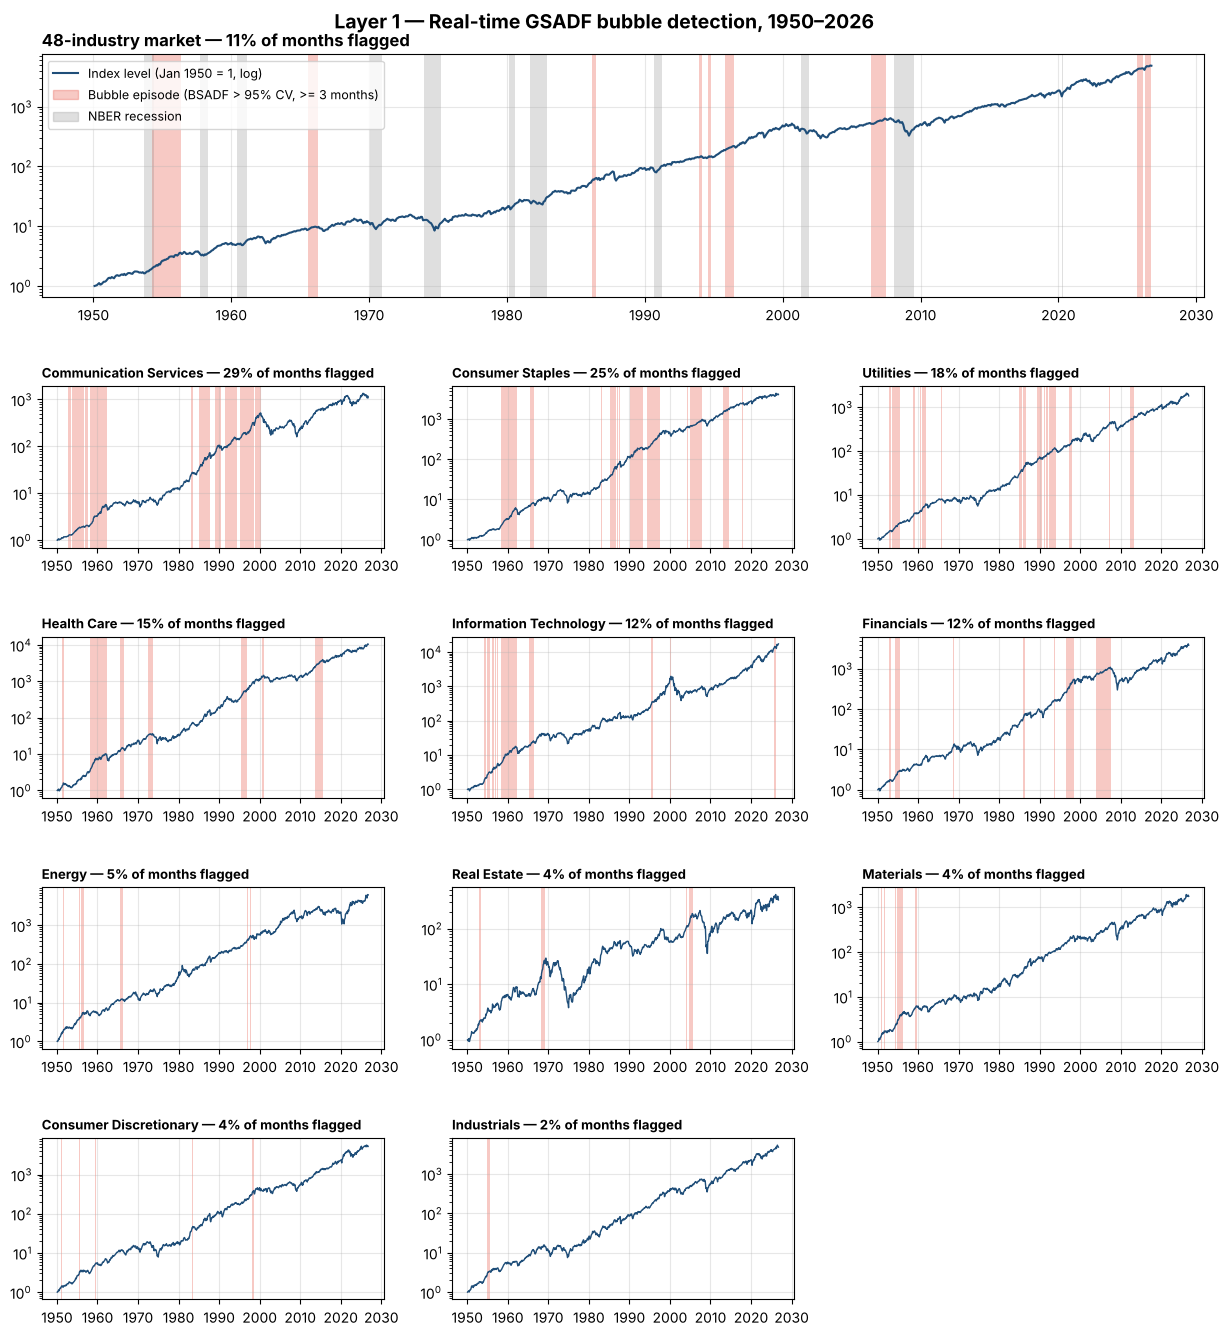

In [10]:
PLOT_START = "1950-01-01"
order  = sorted(GICS_MAP, key=lambda s: -sector_psy[s]["Bubble"].loc[PLOT_START:END].mean())
panels = [(MKT_NAME, mkt_m, mkt_psy)] + [(sec, sector_px[sec], sector_psy[sec]) for sec in order]

fig = plt.figure(figsize=(15, 15))
gs = fig.add_gridspec(5, 3, height_ratios=[1.5, 1, 1, 1, 1], hspace=0.5, wspace=0.2, top=0.94)
fig.suptitle(f"Layer 1 — Real-time GSADF bubble detection, 1950–{END:%Y}", fontsize=14, fontweight="bold", y=0.97)
for k, (name, px, sig) in enumerate(panels):
    ax = fig.add_subplot(gs[0, :] if k == 0 else gs[1 + (k - 1) // 3, (k - 1) % 3])
    px, sig = px.loc[PLOT_START:END], sig.loc[PLOT_START:END]
    ax.plot(px.index, px / px.iloc[0], color="#1f4e79", lw=1.5 if k == 0 else 1)
    for _, ep in episodes(sig["Bubble"]).iterrows():
        ax.axvspan(ep["Start"] - pd.offsets.MonthBegin(1), ep["End"], color="#e74c3c", alpha=0.3, lw=0)
    if k == 0:
        rec = usrec.loc[PLOT_START:].eq(1)
        ax.fill_between(rec.index, 0, 1, where=rec.values, step="pre", color="gray", alpha=0.25, lw=0,
                        transform=ax.get_xaxis_transform())
        ax.legend(handles=[Line2D([], [], color="#1f4e79", label="Index level (Jan 1950 = 1, log)"),
                           Patch(color="#e74c3c", alpha=0.3, label="Bubble episode (BSADF > 95% CV, >= 3 months)"),
                           Patch(color="gray", alpha=0.25, label="NBER recession")], loc="upper left", fontsize=9)
    ax.set_yscale("log")
    ax.set_title(f"{name} — {sig['Bubble'].mean():.0%} of months flagged", loc="left",
                 fontsize=12 if k == 0 else 9.5, fontweight="bold")
    ax.grid(True, alpha=0.3)
save(fig, "layer1_gsadf_bubbles")

## 2.4 PSY signal for the 48 industries
* **Purpose:** Produce the industry-level bubble flag and the continuous signal strength used later as model inputs.
* **Method:** PSY is run on each industry's return history. Months with fewer than 10 firms are set to missing.

In [11]:
ind_psy    = pd.DataFrame(index=ret.index, columns=INDS, dtype=float)   # 0/1 flag
ind_margin = ind_psy.copy()                                             # BSADF - critical value
for i, ind in enumerate(INDS):
    res, _ = run_psy_returns(ret[ind], seed=SEED + 100 + i)
    ind_psy[ind], ind_margin[ind] = res["Bubble"], res["Margin"]
too_few = nfirms < MIN_FIRMS
ind_psy, ind_margin = ind_psy.mask(too_few), ind_margin.mask(too_few)
pd.Series({"Industry-months with a PSY result": int(ind_psy.notna().sum().sum()),
           "Share flagged as bubble": round(ind_psy.stack().mean(), 4),
           "Industries with a data gap (PSY restarted)": int(((ret.notna() & ret.shift().isna()).sum() > 1).sum())},
          name="Value", dtype=object).to_frame()

,Value
Industry-months with a PSY result,42022
Share flagged as bubble,0.0644
Industries with a data gap (PSY restarted),1


## 2.5 Look-ahead test for Layer 1
* **Purpose:** Prove that the flag at month *t* does not use data after *t*.
* **Method:** Truncation test. PSY is rerun on data cut at a past date; every value up to that date must equal the full-sample run.

In [12]:
rows = []
for name, price, cuts, seed in [(MKT_NAME, mkt_m, ["1987-09-30", "1999-12-31", "2019-12-31"], SEED),
                                ("Information Technology", sector_px["Information Technology"], ["1999-12-31"], SEED + 7)]:
    full, _ = run_psy(price, seed=seed)
    for cut in cuts:
        part, _ = run_psy(price.loc[:cut], seed=seed)
        same = np.allclose(full.loc[part.index], part, equal_nan=True)
        assert same, f"look-ahead in PSY at {cut}"
        rows.append({"Series": name, "Cut date": cut, "Months compared": len(part), "Identical": same})
pd.DataFrame(rows)

,Series,Cut date,Months compared,Identical
0,48-industry market,1987-09-30,734,True
1,48-industry market,1999-12-31,881,True
2,48-industry market,2019-12-31,1121,True
3,Information Technology,1999-12-31,881,True


# Part 3 — Layer 2: Market regimes (HMM)

## 3.1 HMM functions
* **Purpose:** Classify each day into a Low-, Normal- or High-volatility market regime using past data only.
* **Method:** A 3-state Gaussian HMM on two inputs: the daily log return and the log of 21-day realised volatility (annualised with √252). The scaler and the model are refitted at each year end and then **forward-filtered** over the next year. `predict_proba` of `hmmlearn` is not used because it is smoothed with future data. States are named by sorting on fitted volatility, so labels cannot switch between fits.

In [13]:
hmm_df = pd.DataFrame({"Return": mkt_ret_d})
hmm_df["Log_Vol"] = np.log(hmm_df["Return"].rolling(VOL_WINDOW).std() * np.sqrt(TRADING_DAYS))
warmup = int(hmm_df.loc[HMM_START:END, "Log_Vol"].isna().sum())     # rows lost to the rolling window (reported in 3.2)
hmm_df = hmm_df.loc[HMM_START:END].dropna()
VOL_COL = 1

def fit_hmm(X, K=3, seeds=(0,), init=None):
    """Highest log-likelihood over random starts, plus a warm start from last year's model."""
    cands = []
    if init is not None:
        m = GaussianHMM(n_components=K, covariance_type="full", n_iter=200, tol=1e-4, random_state=0, init_params="")
        m.startprob_, m.transmat_ = init.startprob_.copy(), init.transmat_.copy()
        m.means_, m.covars_ = init.means_.copy(), init.covars_.copy()
        cands.append(m)
    cands += [GaussianHMM(n_components=K, covariance_type="full", n_iter=200, tol=1e-4, random_state=s) for s in seeds]
    best, best_ll = None, -np.inf
    for m in cands:
        try:
            ll = m.fit(X).score(X)
        except Exception:
            continue
        if np.isfinite(ll) and ll > best_ll:
            best, best_ll = m, ll
    return best

def hmm_filter(model, X):
    """Forward filter: P(state_t | data up to t)."""
    K = model.n_components
    log_b = np.column_stack([stats.multivariate_normal(model.means_[k], model.covars_[k], allow_singular=True).logpdf(X)
                             for k in range(K)])
    alpha = np.zeros((len(X), K))
    a = model.startprob_ * np.exp(log_b[0] - log_b[0].max())
    alpha[0] = a / a.sum()
    for t in range(1, len(X)):
        a = (alpha[t - 1] @ model.transmat_) * np.exp(log_b[t] - log_b[t].max())
        alpha[t] = a / a.sum() if a.sum() > 0 else alpha[t - 1] @ model.transmat_
    return alpha

def hmm_realtime(df, cache=None):
    """Scaler and model fitted at 31 Dec of year Y-1, forward-filtered over year Y. `cache` reuses earlier fits."""
    out, models, prev = [], {}, None
    for y in range(HMM_RT_START, df.index[-1].year + 1):
        fit_end = pd.Timestamp(f"{y - 1}-12-31")
        if cache and fit_end in cache:
            m, sc, o = cache[fit_end]
        else:
            train = df.loc[:fit_end]
            sc = StandardScaler().fit(train)                        # scaler sees the training window only
            m = fit_hmm(sc.transform(train), init=prev)
            o = np.argsort(m.means_[:, VOL_COL])                    # Low < Normal < High volatility
        models[fit_end], prev = (m, sc, o), m
        hist = df.loc[:f"{y}-12-31"]
        p = hmm_filter(m, sc.transform(hist))[:, o]
        out.append(pd.DataFrame(p, index=hist.index, columns=REGIMES).loc[f"{y}":])
    filt = pd.concat(out)
    return filt, filt.idxmax(axis=1), models

## 3.2 Real-time regimes
* **Purpose:** Run the walk-forward HMM and describe the three regimes.
* **Method:** One fit per year from 1955. The table gives the share of days in each regime and the fitted volatility of each state, averaged over all fits. The names describe volatility relative to the other two states only; "High" is not an extreme state. Asserts check that probabilities sum to 1 and that the volatility ordering holds in every fit.

In [14]:
filt, regime, hmm_rt_models = hmm_realtime(hmm_df)
fit_vol = pd.DataFrame({fd: 100 * np.exp(sc.inverse_transform(m.means_[o])[:, VOL_COL])
                        for fd, (m, sc, o) in hmm_rt_models.items()}, index=REGIMES).T
assert np.allclose(filt.sum(axis=1), 1), "probabilities must sum to 1"
assert (fit_vol.diff(axis=1).iloc[:, 1:] > 0).all().all(), "states must be ordered by volatility in every fit"

regime_m = filt.resample("ME").mean()                               # mean filtered probability of month m (data up to m)
regime_m["Regime"] = regime_m[REGIMES].idxmax(axis=1)
regime_profile = pd.DataFrame({"Share of days": regime.value_counts(normalize=True).reindex(REGIMES),
                               "Ann. volatility % (mean over fits)": fit_vol.mean(),
                               "Months as modal regime": regime_m["Regime"].value_counts().reindex(REGIMES)})
print(f"Sample {hmm_df.index[0].date()} to {hmm_df.index[-1].date()}: {len(hmm_df):,} days, "
      f"{warmup} warm-up rows dropped, {len(hmm_rt_models)} yearly fits")
regime_profile.round(3)

Sample 1950-01-03 to 2026-09-30: 19,395 days, 0 warm-up rows dropped, 72 yearly fits


,Share of days,Ann. volatility % (mean over fits),Months as modal regime
Low volatility,0.170,6.166,145
Normal volatility,0.385,9.687,334
High volatility,0.444,16.713,382


## 3.3 Chart: regimes over time
* **Purpose:** Check visually that the High-volatility regime switches on in known stress periods.
* **Method:** Market index with regime shading, the monthly average filtered probabilities, and daily zooms on the 2007–09 and 2020 episodes.

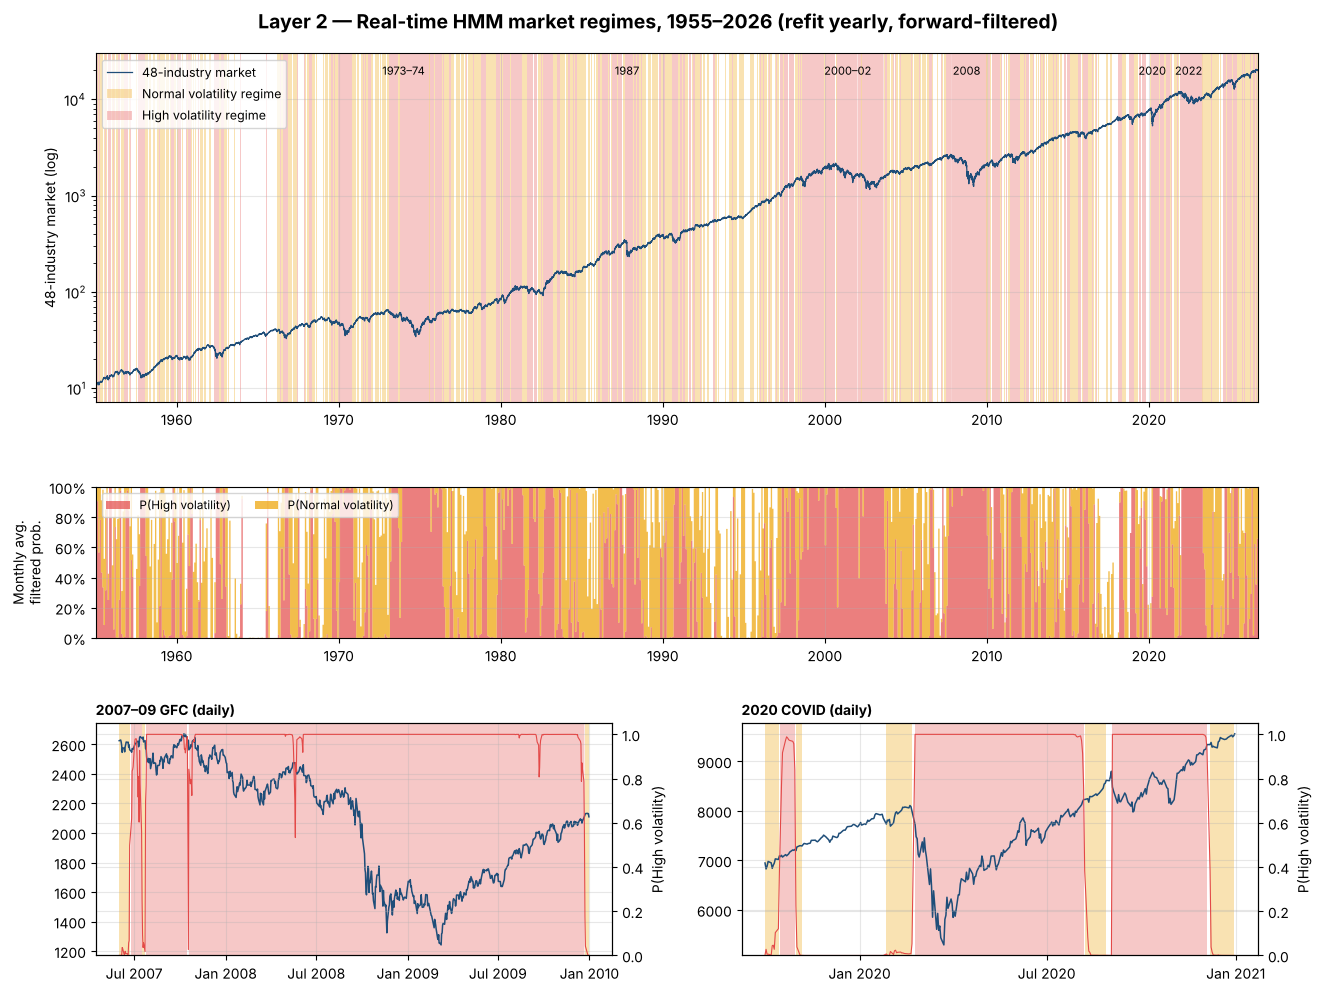

In [15]:
px = mkt_daily.reindex(filt.index)
CRISIS_LABELS = {"1973–74": "1974-01-01", "1987": "1987-10-19", "2000–02": "2001-06-01",
                 "2008": "2008-10-01", "2020": "2020-03-16", "2022": "2022-06-15"}

fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(3, 2, height_ratios=[3, 1.3, 2], hspace=0.35, wspace=0.25, top=0.93)
fig.suptitle(f"Layer 2 — Real-time HMM market regimes, {filt.index[0]:%Y}–{filt.index[-1]:%Y} "
             "(refit yearly, forward-filtered)", fontsize=14, fontweight="bold", y=0.97)
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(px.index, px, color="#1f4e79", lw=0.9, label=MKT_NAME)
for r in REGIMES[1:]:
    ax1.fill_between(regime.index, 0, 1, where=regime.eq(r).values, step="post", color=REGIME_COLORS[r],
                     alpha=0.3, lw=0, transform=ax1.get_xaxis_transform(), label=f"{r} regime")
for lab, d in CRISIS_LABELS.items():
    ax1.text(pd.Timestamp(d), 0.97, lab, transform=ax1.get_xaxis_transform(), ha="center", va="top", fontsize=8)
ax1.set(yscale="log", ylabel=f"{MKT_NAME} (log)", xlim=(filt.index[0], filt.index[-1]))
ax1.legend(loc="upper left", fontsize=9)

ax2 = fig.add_subplot(gs[1, :], sharex=ax1)
ax2.stackplot(regime_m.index, regime_m[REGIMES[2]], regime_m[REGIMES[1]], step="post", alpha=0.7,
              labels=[f"P({REGIMES[2]})", f"P({REGIMES[1]})"], colors=[REGIME_COLORS[REGIMES[2]], REGIME_COLORS[REGIMES[1]]])
ax2.set(ylim=(0, 1), ylabel="Monthly avg.\nfiltered prob.")
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax2.legend(loc="upper left", ncol=2, fontsize=8.5)

for k, (title, a, b) in enumerate([("2007–09 GFC (daily)", "2007-06-01", "2009-12-31"),
                                   ("2020 COVID (daily)", "2019-10-01", "2020-12-31")]):
    ax = fig.add_subplot(gs[2, k])
    for r in REGIMES[1:]:
        ax.fill_between(regime.loc[a:b].index, 0, 1, where=regime.loc[a:b].eq(r).values, step="post",
                        color=REGIME_COLORS[r], alpha=0.3, lw=0, transform=ax.get_xaxis_transform())
    ax.plot(px.loc[a:b], color="#1f4e79", lw=1.1)
    axr = ax.twinx()
    axr.plot(filt.loc[a:b, "High volatility"], color=REGIME_COLORS["High volatility"], lw=0.8)
    axr.set(ylim=(0, 1.05), ylabel="P(High volatility)")
    ax.set_title(title, loc="left", fontsize=10, fontweight="bold")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
for ax in fig.axes:
    ax.grid(True, alpha=0.3)
save(fig, "layer2_hmm_regimes")

## 3.4 Validation against known crises and NBER recessions
* **Purpose:** Give the regimes a meaning that a person can check, instead of leaving them as state numbers.
* **Method:** For each crisis, the peak and trough of the index are found inside a search window (ex-post, validation only) and the share of High-volatility days is counted. The last row gives the same share over all days: the High-volatility state covers a large part of the sample, so a high share inside a crisis must be read against that reference. The second table compares regime shares in NBER recessions and expansions. The state is a broad volatility regime, not a crisis or recession detector.

In [16]:
CRISIS_SEARCH = {"1973-74 oil shock": ("1972-06-01", "1974-12-31"), "1987 crash": ("1987-06-01", "1987-12-31"),
                 "2000-02 dot-com": ("2000-01-01", "2002-12-31"), "2007-09 GFC": ("2007-06-01", "2009-06-30"),
                 "2020 COVID": ("2020-01-01", "2020-06-30"), "2022 rates": ("2021-11-01", "2022-12-31")}
rows = []
for name, (a, b) in CRISIS_SEARCH.items():
    w = mkt_daily.loc[a:b]
    peak, trough = w.idxmax(), w.loc[w.idxmax():].idxmin()
    r = regime.loc[peak:trough]
    first = r[r == "High volatility"].index.min()
    rows.append({"Crisis (peak to trough)": name, "Days": len(r), "% High volatility": (r == "High volatility").mean() * 100,
                 "Days from peak to first High-volatility day": (first - peak).days if pd.notna(first) else np.nan})
rows.append({"Crisis (peak to trough)": "All days (reference)", "Days": len(regime),
             "% High volatility": (regime == "High volatility").mean() * 100})
crisis_check = pd.DataFrame(rows).set_index("Crisis (peak to trough)")

rec_d = pd.Series(usrec.set_axis(usrec.index.to_period("M")).reindex(regime.index.to_period("M")).values, index=regime.index)
ok = rec_d.notna()
rec_tab = pd.crosstab(rec_d[ok].map({1.0: "NBER recession", 0.0: "Expansion"}).rename("Period"),
                      regime[ok].rename("Regime"), normalize="index").reindex(columns=REGIMES) * 100
display(crisis_check.round(1), rec_tab.round(1))

,Days,% High volatility,Days from peak to first High-volatility day
Crisis (peak to trough),,,
1973-74 oil shock,437,87.4,34.0
1987 crash,72,94.4,6.0
2000-02 dot-com,526,93.3,27.0
2007-09 GFC,356,99.4,0.0
2020 COVID,24,87.5,5.0
2022 rates,198,100.0,0.0
All days (reference),18057,44.4,NaN


Regime,Low volatility,Normal volatility,High volatility
Period,,,
Expansion,18.9,41.9,39.2
NBER recession,3.5,13.6,82.9


## 3.5 Look-ahead test for Layer 2
* **Purpose:** Prove that the regime at day *t* does not use data after *t*.
* **Method:** Truncation test in two parts: (1) filtering data cut at a past date must reproduce the same probabilities; (2) refitting at the last fit date before the cut must reproduce the same parameters.

In [17]:
rows = []
for cut in ["1987-10-30", "2008-12-31", "2020-03-31"]:
    part, reg_p, _ = hmm_realtime(hmm_df.loc[:cut], cache=hmm_rt_models)
    same_filter = np.allclose(filt.loc[part.index].values, part.values, atol=1e-10) and regime.loc[reg_p.index].equals(reg_p)
    fd = max(d for d in hmm_rt_models if d <= pd.Timestamp(cut))
    prev = hmm_rt_models.get(fd - pd.DateOffset(years=1))
    train = hmm_df.loc[:fd]
    sc = StandardScaler().fit(train)
    m = fit_hmm(sc.transform(train), init=None if prev is None else prev[0])
    m0, sc0, _ = hmm_rt_models[fd]
    same_fit = np.allclose(sc.mean_, sc0.mean_) and np.allclose(m.means_, m0.means_)
    assert same_filter and same_fit, f"look-ahead in the HMM at {cut}"
    rows.append({"Cut date": cut, "Days compared": len(part), "Filter identical": same_filter,
                 "Refit date": f"{fd:%Y-%m-%d}", "Refit identical": same_fit})
pd.DataFrame(rows)

,Cut date,Days compared,Filter identical,Refit date,Refit identical
0,1987-10-30,8256,True,1986-12-31,True
1,2008-12-31,13594,True,2008-12-31,True
2,2020-03-31,16424,True,2019-12-31,True


# Part 4 — Features and labels

## 4.1 Industry features
* **Purpose:** Describe each industry at month *t* with information available at *t* only.
* **Method:** Every continuous feature is turned into a **cross-sectional percentile rank** among eligible industries in the same month. Ranks keep the same scale in 1935 and in 2020, so a model trained on old data is not asked to extrapolate. Three features target bubbles specifically: `EW_Tilt` (equal- minus value-weighted 24-month return, a proxy for a tilt towards small and young firms), `Net24_x_VolChg` (volatility that rises during a run-up) and `PSY_Margin` (strength of the Layer 1 signal).

| Group | Features |
|---|---|
| Price run-up | `RunUp` flag, `Net24` (24M return net of market), `Accel` (last 12M versus the 12M before) |
| Volatility | `Vol_pre` (before the run-up), `Vol6` (last 6 months), `Vol_Chg` (change in volatility) |
| Issuance / valuation | `Firms_Chg24` (growth in firm count), `BM` (book-to-market) |
| Bubble signals | `EW_Tilt`, `Net24_x_VolChg`, `PSY_Margin` |
| Own history (not ranked) | `Vol_Own`, `R24_Own` (percentile within the industry's own last 10 years), `DD60` (distance from the 5-year high) |

Ranks remove everything that all industries share, including the level of market-wide risk. The own-history group puts that level back; it is tested in the ablation (6.7) and is not part of the main model.

In [18]:
def lag_return(r, k):
    # cumulative k-month return ending at t; missing if any month in the window is missing
    return np.expm1(np.log1p(r).rolling(k, min_periods=k).sum())

eligible = nfirms >= MIN_FIRMS
xrank = lambda df: df.where(eligible).rank(axis=1, pct=True)        # rank within the month, eligible industries only

price = np.exp(np.log1p(ret).cumsum())                              # total-return index of each industry
R24, R60 = lag_return(ret, 24), lag_return(ret, 60)
Net24 = R24.sub(lag_return(mkt, 24), axis=0)

vol_d = dret.groupby(dret.index.to_period("M")).std() * np.sqrt(TRADING_DAYS)   # daily data -> x sqrt(252)
vol_d = vol_d.set_axis(vol_d.index.to_timestamp("M")).reindex(ret.index)
vol6  = vol_d.rolling(6, min_periods=4).mean()

nf_pos = nfirms.where(nfirms > 0)
bm = be_me.where(be_me > 0)
bm.index = pd.to_datetime([f"{int(y)}-{BM_MONTH:02d}-01" for y in bm.index]) + pd.offsets.MonthEnd(0)
bm = bm.reindex(bm.index.union(ret.index)).ffill(limit=11).reindex(ret.index)    # annual value kept <= 11 months

RAW = {"Net24":          Net24,
       "Accel":          R24 - lag_return(ret, 12).shift(12),
       "Vol_pre":        ret.shift(24).rolling(12, min_periods=10).std() * np.sqrt(12),   # monthly data -> x sqrt(12)
       "Vol6":           vol6,
       "Vol_Chg":        np.log(vol6 / vol_d.shift(12).rolling(12, min_periods=8).mean()),
       "Firms_Chg24":    np.log(nf_pos / nf_pos.shift(24)),
       "BM":             bm,
       "EW_Tilt":        lag_return(ret_ew, 24) - R24,
       "PSY_Margin":     ind_margin}
RAW["Net24_x_VolChg"] = RAW["Net24"] * RAW["Vol_Chg"]

RUNUP = ((R24 >= RUNUP_2Y) & (Net24 >= RUNUP_2Y) & (R60 >= RUNUP_5Y)).astype(float).where(R60.notna() & Net24.notna())
own_pct = lambda df: df.rolling(120, min_periods=60).rank(pct=True)     # percentile within the industry's own last 10 years
W = {"RunUp": RUNUP, **{f"{k}_R": xrank(v) for k, v in RAW.items()}, **RAW,
     "Vol_Own": own_pct(vol6), "R24_Own": own_pct(R24), "DD60": price / price.rolling(60, min_periods=60).max() - 1,
     "R24": R24, "DD12": price / price.rolling(12, min_periods=12).max() - 1}

FEATS_VOL    = ["Vol_pre_R", "Vol6_R"]                                               # volatility-only baseline
FEATS_MAIN   = ["RunUp", "Net24_R", "Accel_R", "Vol_pre_R", "Vol6_R", "Vol_Chg_R", "Firms_Chg24_R", "BM_R"]
FEATS_BUBBLE = ["EW_Tilt_R", "Net24_x_VolChg_R", "PSY_Margin_R"]
FEATS_OWN    = ["Vol_Own", "R24_Own", "DD60"]
FEATS_RAW    = ["RunUp", "Net24", "Accel", "Vol_pre", "Vol6", "Vol_Chg", "Firms_Chg24", "BM"]       # no ranks at all, robustness only
assert not any(f.endswith("_R") for f in FEATS_RAW)
FEAT_GROUP   = {"Price run-up": ["RunUp", "Net24_R", "Accel_R"], "Volatility": ["Vol_pre_R", "Vol6_R", "Vol_Chg_R"],
                "Issuance / valuation": ["Firms_Chg24_R", "BM_R"]}

## 4.2 Crash labels
* **Purpose:** Define what the model has to predict.
* **Method:** The headline label `Crash_H(t)` = 1 if the industry price **divided by the market** falls at least 30% from its running peak within the next *H* months. A fall that only mirrors the whole market does not count, so the label isolates industry-specific crashes and is not driven by market beta. The label is missing when the future window is incomplete, so unfinished windows are never counted as "no crash". The secondary label `CrashAbs` is the absolute definition of Greenwood et al. (a 40% fall of the industry price itself); it is kept for comparison in 6.4 and 11.1.

In [19]:
def crash_label(px, H, dd):
    run_max, max_dd = px.copy(), pd.DataFrame(0.0, index=px.index, columns=px.columns)
    for k in range(1, H + 1):
        run_max = np.fmax(run_max, px.shift(-(k - 1)))
        max_dd  = np.fmax(max_dd, 1 - px.shift(-k) / run_max)
    n_obs = ret.notna().astype(int).rolling(H, min_periods=H).sum().shift(-H)
    complete = px.shift(-H).notna() & px.notna() & n_obs.eq(H)
    return (max_dd >= dd).astype(float).where(complete)

rel_px    = price.div(np.exp(np.log1p(mkt).cumsum()), axis=0)       # industry price relative to the market
CRASH     = {H: crash_label(rel_px, H, REL_DD) for H in H_LIST}     # headline: relative to the market
CRASH_ABS = crash_label(price, MAIN_H, ABS_DD)                      # secondary: absolute

both = CRASH[MAIN_H].stack().to_frame("rel").join(CRASH_ABS.stack().rename("abs")).dropna()
label_table = pd.DataFrame(
    [{"Label": f"Crash_{H} (>= {REL_DD:.0%} vs market in {H}M)", "Base rate": CRASH[H].stack().mean(),
      "Last labelled month": f"{CRASH[H].dropna(how='all').index.max():%Y-%m}"} for H in H_LIST] +
    [{"Label": f"CrashAbs_{MAIN_H} (>= {ABS_DD:.0%} in {MAIN_H}M)", "Base rate": CRASH_ABS.stack().mean(),
      "Last labelled month": f"{CRASH_ABS.dropna(how='all').index.max():%Y-%m}"}]).set_index("Label")
print(f"Share of {MAIN_H}M absolute crashes that are also relative crashes: {both.loc[both['abs'] == 1, 'rel'].mean():.1%}")
label_table.round(3)

Share of 24M absolute crashes that are also relative crashes: 65.0%


,Base rate,Last labelled month
Label,,
Crash_6 (>= 30% vs market in 6M),0.020,2026-03
Crash_12 (>= 30% vs market in 12M),0.065,2025-09
Crash_24 (>= 30% vs market in 24M),0.175,2024-09
CrashAbs_24 (>= 40% in 24M),0.139,2024-09


## 4.3 Crash events and the business cycle
* **Purpose:** Measure how many industry crashes simply come with a recession.
* **Method:** Descriptive, with hindsight. An absolute crash event starts in the first month an industry is at least 40% below its 24-month high; a new event needs more than 24 months since the previous one. Events are compared with NBER recession months. A high share inside recessions means the absolute definition mostly captures market-wide falls, which is why the relative label is the headline.

In [20]:
dd24 = price / price.rolling(24, min_periods=1).max() - 1
event_rows = []
for ind in INDS:
    last = None
    for d in dd24.index[dd24[ind] <= -ABS_DD]:
        if last is None or (d.to_period("M") - last.to_period("M")).n > 24:
            event_rows.append({"Industry": ind, "Onset": d})
            last = d
EVENTS = pd.DataFrame(event_rows)

rec_m = usrec.reindex(ret.index).ffill(limit=FRED_FFILL)
near  = rec_m.rolling(25, center=True, min_periods=1).max()         # recession within +/- 12 months (ex-post description)
ev = EVENTS[EVENTS["Onset"] >= rec_m.first_valid_index()]
top_years = ev.groupby(ev["Onset"].dt.year).size().nlargest(5)
pd.Series({"Crash events": len(ev),
           "Onset during a recession (%)": round(100 * ev["Onset"].map(rec_m).eq(1).mean(), 1),
           "Share of all months in recession (%)": round(100 * rec_m.mean(), 1),
           "Onset within 12 months of a recession (%)": round(100 * ev["Onset"].map(near).eq(1).mean(), 1),
           "Years with the most onsets": ", ".join(f"{y} ({n})" for y, n in top_years.items())}, name="Value", dtype=object).to_frame()

,Value
Crash events,360
Onset during a recession (%),62.5
Share of all months in recession (%),16.7
Onset within 12 months of a recession (%),72.2
Years with the most onsets,"2008 (35), 1937 (26), 1974 (22), 1970 (20), 1930 (19)"


## 4.4 Panel: one row per industry-month
* **Purpose:** Put features, labels and weights in one table for the models.
* **Method:** Rows need at least 10 firms and a complete main feature set. The number of rows removed at each step is reported instead of being dropped silently. A row is `Masked` when the industry is already 20% below its 12-month high: such months are not early warnings, so they are excluded from training and from evaluation. HMM probabilities are attached for the ablation test.

In [21]:
idx  = pd.MultiIndex.from_product([ret.index, INDS], names=["Date", "Industry"])
wide = {**W, "NFirms": nfirms, "MCap": mcap, "PSY_Bubble": ind_psy,
        **{f"Crash_{H}": CRASH[H] for H in H_LIST}, f"CrashAbs_{MAIN_H}": CRASH_ABS}
full = pd.DataFrame({k: v.reindex(index=ret.index, columns=INDS).values.ravel() for k, v in wide.items()}, index=idx)
full = full[full["NFirms"].notna()]
enough = full[full["NFirms"] >= MIN_FIRMS]
panel  = enough.dropna(subset=FEATS_MAIN).copy()
panel["Masked"] = panel["DD12"] <= MASK_DD12
panel["Year"]   = panel.index.get_level_values("Date").year
for r in REGIMES[1:]:
    panel[f"HMM_{r}"] = regime_m[r].reindex(panel.index.get_level_values("Date")).values
panel["Net24_x_HighVol"] = panel["Net24_R"] * panel["HMM_High volatility"]

assert not panel.index.duplicated().any()
assert np.isfinite(panel[FEATS_MAIN]).all().all()
assert panel[FEATS_MAIN].drop(columns="RunUp").stack().between(0, 1).all(), "rank features must lie in [0, 1]"
pd.Series({"Industry-months with data": len(full),
           f"Removed: fewer than {MIN_FIRMS} firms": len(full) - len(enough),
           "Removed: incomplete feature history (warm-up)": len(enough) - len(panel),
           "Panel rows": len(panel),
           "First year": panel["Year"].min(), "Last year": panel["Year"].max(),
           "Masked rows (already falling) %": round(100 * panel["Masked"].mean(), 1),
           "Strict run-up rows (RunUp = 1) %": round(100 * panel["RunUp"].mean(), 2),
           "Rows with all bubble-signal and own-history features %": round(100 * panel[FEATS_BUBBLE + FEATS_OWN].notna().all(axis=1).mean(), 1)},
          name="Value", dtype=object).to_frame()

,Value
Industry-months with data,57744
Removed: fewer than 10 firms,15047
Removed: incomplete feature history (warm-up),1262
Panel rows,41435
First year,1931
Last year,2026
Masked rows (already falling) %,12.3
Strict run-up rows (RunUp = 1) %,0.8
Rows with all bubble-signal and own-history features %,98.7


## 4.5 Feature correlation
* **Purpose:** See which features carry the same information.
* **Method:** Spearman rank correlation over the whole panel. Strongly correlated features share importance in a tree model and can flip sign in a Logit, so effects are read by feature group (Part 7).

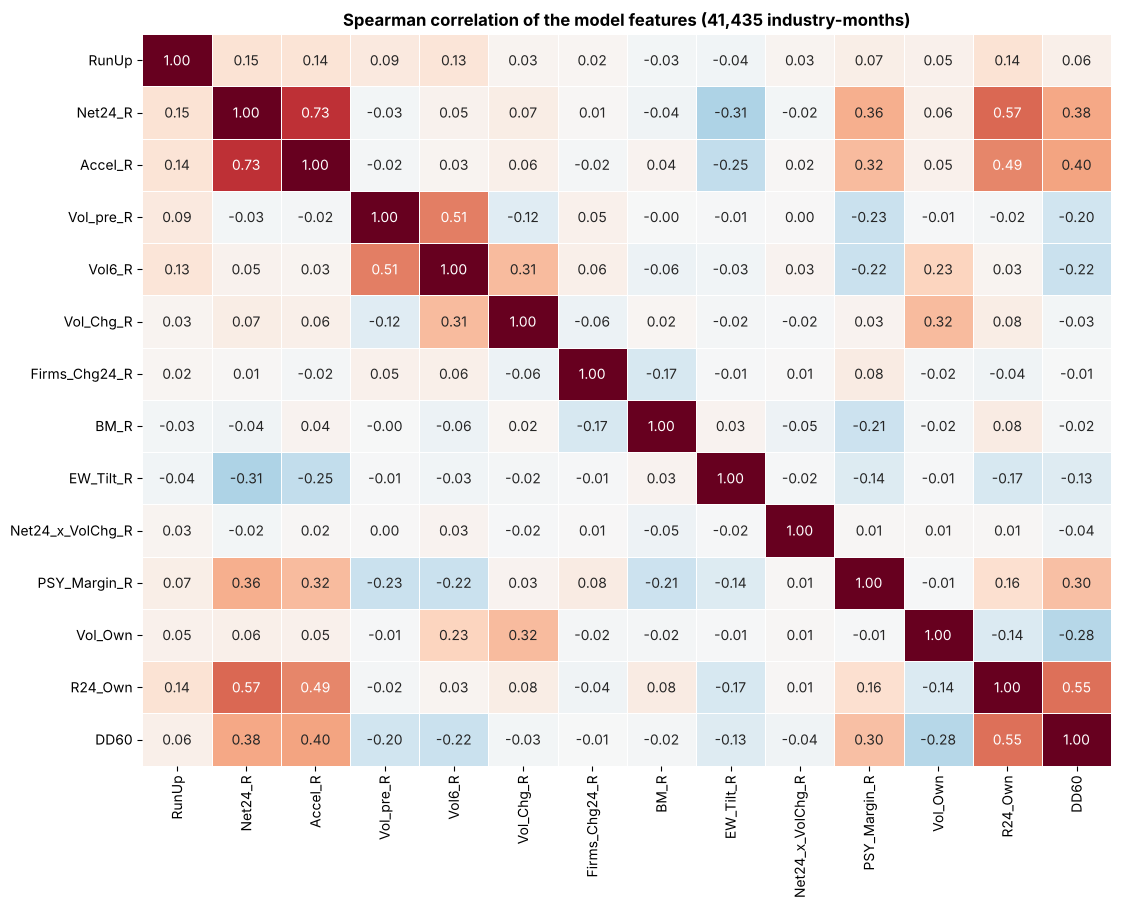

In [22]:
fig, ax = plt.subplots(figsize=(12.5, 9.5))
sns.heatmap(panel[FEATS_MAIN + FEATS_BUBBLE + FEATS_OWN].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, linewidths=0.5, cbar=False, ax=ax)
ax.set_title(f"Spearman correlation of the model features ({len(panel):,} industry-months)", fontsize=12, fontweight="bold")
save(fig, "feature_correlation")

# Part 5 — Layer 3: Walk-forward models

## 5.1 Models
* **Purpose:** Define the benchmark ladder: base rate → volatility-only Logit → Logit → Random Forest.
* **Method:** Each model is a `Pipeline`, so the winsoriser and the scaler are fitted on the training rows only. `Logit-Vol` uses two volatility ranks and nothing else. If it ranks industries as well as the full models, the system is a volatility ranker and not a bubble detector.

In [23]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip continuous features to training-set quantiles; 0/1 flags are left unchanged."""
    def __init__(self, lower=WINSOR[0], upper=WINSOR[1]):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_, self.hi_ = np.quantile(X, [self.lower, self.upper], axis=0)
        flag = np.array([np.unique(c).size <= 2 for c in X.T])
        self.lo_[flag], self.hi_[flag] = -np.inf, np.inf
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

def make_model(kind):
    if kind == "rf":
        clf = RandomForestClassifier(n_estimators=200, max_depth=4, min_samples_leaf=300, max_samples=0.5,
                                     n_jobs=-1, random_state=SEED)
        return Pipeline([("clip", Winsorizer()), ("clf", clf)])
    return Pipeline([("clip", Winsorizer()), ("scale", StandardScaler()), ("clf", LogisticRegression(C=1.0, max_iter=3000))])

MODEL_SPECS = {VOL_MODEL:   ("logit", FEATS_VOL),
               BENCH_MODEL: ("logit", FEATS_MAIN),
               MAIN_MODEL:  ("rf",    FEATS_MAIN)}
MODELS = list(MODEL_SPECS)

## 5.2 Walk-forward engine
* **Purpose:** Produce out-of-sample probabilities with one function that every later test reuses.
* **Method:** For each test year *Y* the model is fitted on rows dated up to 31 December of *Y−1*.
    * **Embargo:** a training row is used only if its label was already known at the fit date (*t + H* ≤ fit date).
    * **Time decay:** training rows are weighted by 0.5^(age / half-life), so the oldest data do not dominate. The base rate is the weighted crash rate of the same training rows. The half-life is chosen in 5.3.
    * **Masked rows** are excluded from training.

In [24]:
CARRY = ["Masked", "MCap", "RunUp", "PSY_Bubble", "R24", "Net24_R"]     # columns copied to the prediction table

def walk_forward(label, specs, H, rows=None, half_life=None, keep_years=(), years=None):
    """Returns (pred, fitted, insample): out-of-sample predictions, models of `keep_years`, in-sample AUC per fit."""
    data = panel if rows is None else rows
    half_life = HALF_LIFE if half_life is None else half_life
    lab = data[data[label].notna() & ~data["Masked"]]
    lab_dates = lab.index.get_level_values("Date")
    preds, fitted, insample = [], {}, []
    for year in (years or range(FIRST_TEST_YEAR, data["Year"].max() + 1)):
        fit_date = pd.Timestamp(f"{year - 1}-12-31")
        train = lab[lab_dates <= fit_date - pd.DateOffset(months=H)]            # embargo
        test = data[data["Year"] == year]
        if test.empty or len(train) < MIN_TRAIN or train[label].nunique() < 2:
            continue
        age = np.asarray((fit_date - train.index.get_level_values("Date")).days) / 365.25
        w = 0.5 ** (age / half_life)                                            # half_life = inf gives equal weights
        y_tr = train[label].astype(int).values
        out = test[[label] + CARRY].rename(columns={label: "y"})
        out["Base rate"] = np.average(y_tr, weights=w)
        for name, (kind, feats) in specs.items():
            ok_tr, ok_te = train[feats].notna().all(axis=1).values, test[feats].notna().all(axis=1).values
            out[name] = np.nan
            if ok_tr.sum() < MIN_TRAIN or len(set(y_tr[ok_tr])) < 2 or not ok_te.any():
                continue
            model = make_model(kind).fit(train.loc[ok_tr, feats], y_tr[ok_tr], clf__sample_weight=w[ok_tr])
            out.loc[ok_te, name] = model.predict_proba(test.loc[ok_te, feats])[:, 1]
            p_in, y_in, yr_in = model.predict_proba(train.loc[ok_tr, feats])[:, 1], y_tr[ok_tr], train["Year"].values[ok_tr]
            insample.append({"Year": year, "Model": name,                        # AUC inside each training year, averaged
                             "AUC in-sample": np.mean([roc_auc_score(y_in[yr_in == k], p_in[yr_in == k])
                                                       for k in np.unique(yr_in) if 0 < y_in[yr_in == k].mean() < 1])})
            if year in keep_years:
                fitted[(year, name)] = model
        preds.append(out)
    return pd.concat(preds).sort_index(), fitted, pd.DataFrame(insample)

## 5.3 Choose the half-life before the test period
* **Purpose:** Set the time-decay half-life without looking at the test years.
* **Method:** Nested walk-forward. The main and benchmark models are run over 1945–1959 only, once for each candidate half-life. The half-life with the highest pooled AUC of the main model on those validation years is locked and used for every test year from 1960. The rule was fixed before the run.

In [25]:
valid_rows = []
for hl in HALF_LIFE_GRID:
    v, _, _ = walk_forward(f"Crash_{MAIN_H}", {m: MODEL_SPECS[m] for m in [BENCH_MODEL, MAIN_MODEL]}, MAIN_H, half_life=hl, years=VALID_YEARS)
    v = v[~v["Masked"] & v["y"].notna()]
    valid_rows.append({"Half-life (years)": hl, "Rows": len(v), "Crash rate": v["y"].mean(),
                       **{f"AUC {m}": roc_auc_score(v["y"], v[m]) for m in [MAIN_MODEL, BENCH_MODEL]},
                       **{f"Brier {m}": ((v[m] - v["y"]) ** 2).mean() for m in [MAIN_MODEL, BENCH_MODEL]}})
half_life_table = pd.DataFrame(valid_rows).set_index("Half-life (years)")
HALF_LIFE = half_life_table[f"AUC {MAIN_MODEL}"].idxmax()
half_life_table["Chosen"] = half_life_table.index == HALF_LIFE
half_life_table.round(4)

,Rows,Crash rate,AUC RandomForest,AUC Logit,Brier RandomForest,Brier Logit,Chosen
Half-life (years),,,,,,,
10.0,4382,0.0504,0.5623,0.5416,0.0489,0.0502,False
20.0,4382,0.0504,0.5973,0.5552,0.0493,0.0510,False
40.0,4382,0.0504,0.6126,0.5612,0.0496,0.0516,False
inf,4382,0.0504,0.6147,0.5663,0.0503,0.0524,True


## 5.4 Run the models
* **Purpose:** Fit every model at every horizon, plus the two side tests.
* **Method:**
    * `PRED[H]` — headline (relative) crash label for 6, 12 and 24 months.
    * `PRED_ABS` — absolute crash label at 24 months.
    * `ABL` — ablation at 24 months on identical rows: does adding the bubble signals (Layer 1), the HMM regime (Layer 2) or the own-history features help?

In [26]:
PRED, INSAMPLE = {}, {}
for H in H_LIST:
    PRED[H], fitted, INSAMPLE[H] = walk_forward(f"Crash_{H}", MODEL_SPECS, H, keep_years=EXPLAIN_YEARS.values())
    if H == MAIN_H:
        FITTED = fitted
PRED_ABS, _, _ = walk_forward(f"CrashAbs_{MAIN_H}", MODEL_SPECS, MAIN_H)

HMM_FEATS = [f"HMM_{r}" for r in REGIMES[1:]]
ABL_SETS = {"Main": FEATS_MAIN, "Main + bubble signals": FEATS_MAIN + FEATS_BUBBLE,
            "Main + HMM regime": FEATS_MAIN + HMM_FEATS, "Main + own history": FEATS_MAIN + FEATS_OWN,
            "Main + all": FEATS_MAIN + FEATS_BUBBLE + HMM_FEATS + FEATS_OWN}
ABL_SPECS = {f"{fam} | {name}": (kind, feats + (["Net24_x_HighVol"] if kind == "logit" and HMM_FEATS[0] in feats else []))
             for kind, fam in [("logit", "Logit"), ("rf", "RF")] for name, feats in ABL_SETS.items()}   # a Logit needs the interaction spelled out
abl_rows = panel.dropna(subset=FEATS_BUBBLE + HMM_FEATS + FEATS_OWN)             # same rows for every variant
ABL, _, _ = walk_forward(f"Crash_{MAIN_H}", ABL_SPECS, MAIN_H, rows=abl_rows)

for name, p in {**{f"PRED[{H}]": PRED[H] for H in H_LIST}, "PRED_ABS": PRED_ABS, "ABL": ABL}.items():
    assert p[[c for c in p.columns if c in MODELS or " | " in c]].stack().between(0, 1).all(), f"{name}: P outside [0, 1]"
coverage = pd.DataFrame({name: {"First month": f"{p.index.get_level_values('Date').min():%Y-%m}",
                                "Last month": f"{p.index.get_level_values('Date').max():%Y-%m}",
                                "Rows": len(p), "Labelled rows": int(p["y"].notna().sum())}
                         for name, p in {**{f"Crash_{H}": PRED[H] for H in H_LIST}, f"CrashAbs_{MAIN_H}": PRED_ABS,
                                         "Ablation": ABL}.items()}).T
coverage

,First month,Last month,Rows,Labelled rows
Crash_6,1960-01,2026-09,33360,33125
Crash_12,1960-01,2026-09,33360,32885
Crash_24,1960-01,2026-09,33360,32384
CrashAbs_24,1960-01,2026-09,33360,32384
Ablation,1961-01,2026-09,32950,31974


# Part 6 — Evaluation (out-of-sample, early-warning months)

## 6.1 Metrics and bootstrap
* **Purpose:** Separate three questions that a single AUC mixes together.
* **Method:**
    * **XS-AUC** — *which industry?* AUC across industries inside each month, averaged over months.
    * **Time-AUC** — *when?* Each row gets its month's average prediction, so only the time dimension is left. The reference is 0.5, the score of any constant forecast. A value below 0.5 means the average forecast is high in the wrong years.
    * **AUC** — pooled, both dimensions together.
    * **BSS** — are the probabilities more accurate than the training base rate? (Brier skill score, 0 = no better.)
    * **Intervals** — moving-block bootstrap over whole months (24-month blocks), because industries crash together and labels overlap.
    * **Alert** — the 5 industries with the highest P(crash) each month, among industries not already falling.

In [27]:
def block_positions(n, seed=SEED):
    rng = np.random.default_rng(seed)                               # same seed -> comparisons between models are paired
    for _ in range(N_BOOT):
        starts = rng.integers(0, n - BLOCK + 1, size=int(np.ceil(n / BLOCK)))
        yield np.concatenate([np.arange(s, s + BLOCK) for s in starts])[:n]

def early_warning(pred):
    return pred[~pred["Masked"] & pred["y"].notna()]

def xs_auc(df, col):
    return pd.Series({d: roc_auc_score(g["y"], g[col]) for d, g in df.groupby(level="Date")
                      if g["y"].nunique() == 2 and g[col].nunique() > 1}, dtype=float)

def bss(y, p, base):
    return 1 - np.mean((p - y) ** 2) / np.mean((base - y) ** 2)

def metric_draws(df, col):
    """Point estimate (row 0) and bootstrap draws of [XS-AUC, Time-AUC, AUC, PR lift, BSS] for one model column."""
    y, p, base = df["y"].values.astype(int), df[col].values, df["Base rate"].values
    p_time = df.groupby(level="Date")[col].transform("mean").values
    codes, months = pd.factorize(df.index.get_level_values("Date"))
    rows_of = [np.flatnonzero(codes == k) for k in range(len(months))]
    xs = xs_auc(df, col).reindex(months).values
    def calc(pos):
        ix = np.concatenate([rows_of[k] for k in pos])
        if y[ix].min() == y[ix].max():
            return [np.nan] * 5
        x = xs[pos]
        return [np.nanmean(x) if np.isfinite(x).any() else np.nan, roc_auc_score(y[ix], p_time[ix]),
                roc_auc_score(y[ix], p[ix]), average_precision_score(y[ix], p[ix]) / y[ix].mean(), bss(y[ix], p[ix], base[ix])]
    return np.array([calc(np.arange(len(months)))] + [calc(pos) for pos in block_positions(len(months))])

METRICS = ["XS-AUC", "Time-AUC", "AUC", "PR lift", "BSS"]

def evaluate(df, models):
    df = df.dropna(subset=["y", "Base rate"] + models).sort_index()
    out = {}
    for m in models:
        d = metric_draws(df, m)
        lo, hi = np.nanpercentile(d[1:], [2.5, 97.5], axis=0)
        out[m] = {"N": len(df), "Crash rate": df["y"].mean(), **dict(zip(METRICS, d[0])),
                  **{f"{k} lo": v for k, v in zip(METRICS, lo)}, **{f"{k} hi": v for k, v in zip(METRICS, hi)}}
    return pd.DataFrame(out).T.astype({"N": int})

def paired_diff(df, a, b):
    """Bootstrap difference a - b on identical rows and months; p = two-sided bootstrap p-value."""
    df = df.dropna(subset=["y", "Base rate", a, b]).sort_index()
    d = metric_draws(df, a) - metric_draws(df, b)
    row = {}
    for k, name in enumerate(METRICS):
        if name == "PR lift":
            continue
        draws = d[1:, k][np.isfinite(d[1:, k])]
        row.update({f"Δ{name}": d[0, k], f"Δ{name} lo": np.percentile(draws, 2.5), f"Δ{name} hi": np.percentile(draws, 97.5),
                    f"p {name}": max(2 * min((draws <= 0).mean(), (draws >= 0).mean()), 1 / N_BOOT)})
    return row

def top_k_alert(pred, model, k=ALERT_K):
    p = pred[model].where(~pred["Masked"])
    return p.groupby(level="Date").rank(ascending=False, method="first") <= k

EW = {H: early_warning(PRED[H]) for H in H_LIST}
EW_ABS = early_warning(PRED_ABS)

## 6.2 Scorecard: every horizon
* **Purpose:** Report the out-of-sample skill of each model against the base rate.
* **Method:** `Base rate` is the time-only benchmark: the same probability for every industry in a year. It is a lagging quantity: because of the embargo, a wave of crashes enters the training base rate about two years after it happened, and a model built on rank features inherits that level. On the absolute label this pushes Time-AUC well below 0.5 (6.4, 11.1); on the headline label, which removes market-wide falls, it stays close to 0.5. A Time-AUC near 0.5 means no timing skill, so the system is used as a **ranking**; the level of the probabilities is examined separately in 8.4. The 24-month horizon is the headline; 6 and 12 months show whether the result depends on the horizon.

In [28]:
results = {H: evaluate(EW[H], ["Base rate"] + MODELS) for H in H_LIST}
scorecard = pd.concat(results, names=["Horizon (months)", "Model"])
scorecard[["N", "Crash rate", "XS-AUC", "Time-AUC", "AUC", "AUC lo", "AUC hi", "PR lift", "BSS", "BSS lo", "BSS hi"]].round(3)

N  Crash rate  XS-AUC  Time-AUC    AUC  AUC lo  AUC hi  PR lift    BSS  BSS lo  BSS hi
Horizon (months) Model                                                                                                   
6                Base rate     29212       0.007     NaN     0.602  0.602   0.509   0.654    1.508  0.000   0.000   0.000
                 Logit-Vol     29212       0.007   0.841     0.612  0.763   0.644   0.895    7.115  0.013   0.007   0.020
                 Logit         29212       0.007   0.819     0.585  0.749   0.643   0.879    7.815  0.016   0.007   0.026
                 RandomForest  29212       0.007   0.831     0.610  0.745   0.615   0.883    7.165  0.011   0.006   0.019
12               Base rate     28983       0.035     NaN     0.561  0.561   0.462   0.618    1.159  0.000   0.000   0.000
                 Logit-Vol     28983       0.035   0.783     0.563  0.666   0.594   0.784    3.517  0.022   0.011   0.036
                 Logit         28983       0.035   0.754     0.594  0.657   0.582   0.779    3.421  0.030   0.012   0.055
                 RandomForest  28983       0.035   0.782     0.568  0.671   0.591   0.786    3.413  0.023   0.011   0.039
24               Base rate     28502       0.131     NaN     0.499  0.499   0.421   0.560    0.944  0.000   0.000   0.000
                 Logit-Vol     28502       0.131   0.703     0.502  0.631   0.590   0.700    1.921  0.035   0.021   0.060
                 Logit         28502       0.131   0.678     0.526  0.624   0.584   0.695    1.778  0.036   0.016   0.063
                 RandomForest  28502       0.131   0.710     0.516  0.628   0.579   0.702    1.872  0.036   0.022   0.057

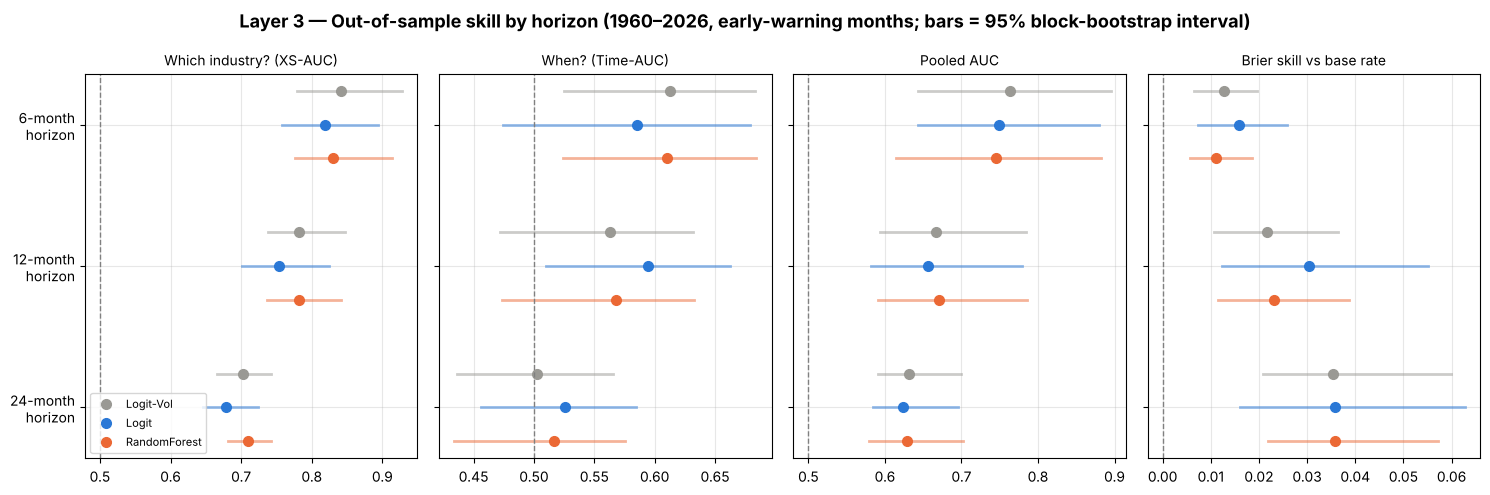

In [29]:
PANELS = [("XS-AUC", 0.5, "Which industry? (XS-AUC)"), ("Time-AUC", 0.5, "When? (Time-AUC)"),
          ("AUC", 0.5, "Pooled AUC"), ("BSS", 0.0, "Brier skill vs base rate")]
ypos = {(H, m): -(i * (len(MODELS) + 1.2) + j) for i, H in enumerate(H_LIST) for j, m in enumerate(MODELS)}
fig, axes = plt.subplots(1, 4, figsize=(15, 5), sharey=True)
fig.suptitle(f"Layer 3 — Out-of-sample skill by horizon ({FIRST_TEST_YEAR}–{END:%Y}, early-warning months; "
             f"bars = 95% block-bootstrap interval)", fontsize=13, fontweight="bold")
for ax, (metric, ref, title) in zip(axes, PANELS):
    for (H, m), y in ypos.items():
        r = results[H].loc[m]
        ax.plot([r[f"{metric} lo"], r[f"{metric} hi"]], [y, y], color=MODEL_COLORS[m], lw=2, alpha=0.5)
        ax.plot(r[metric], y, "o", color=MODEL_COLORS[m], ms=7, label=m if H == H_LIST[0] else None)
    ax.axvline(ref, color="gray", ls="--", lw=1)
    ax.set_title(title, fontsize=10)
    ax.grid(True, alpha=0.3)
axes[0].set_yticks([np.mean([ypos[(H, m)] for m in MODELS]) for H in H_LIST])
axes[0].set_yticklabels([f"{H}-month\nhorizon" for H in H_LIST])
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
save(fig, "layer3_scorecard")

## 6.3 ROC, precision–recall and reliability at 24 months
* **Purpose:** Check ranking quality and whether the probabilities have the right size.
* **Method:** Pooled ROC and precision–recall curves. The reliability panel compares the mean predicted probability with the observed crash frequency in each decile of predicted risk.

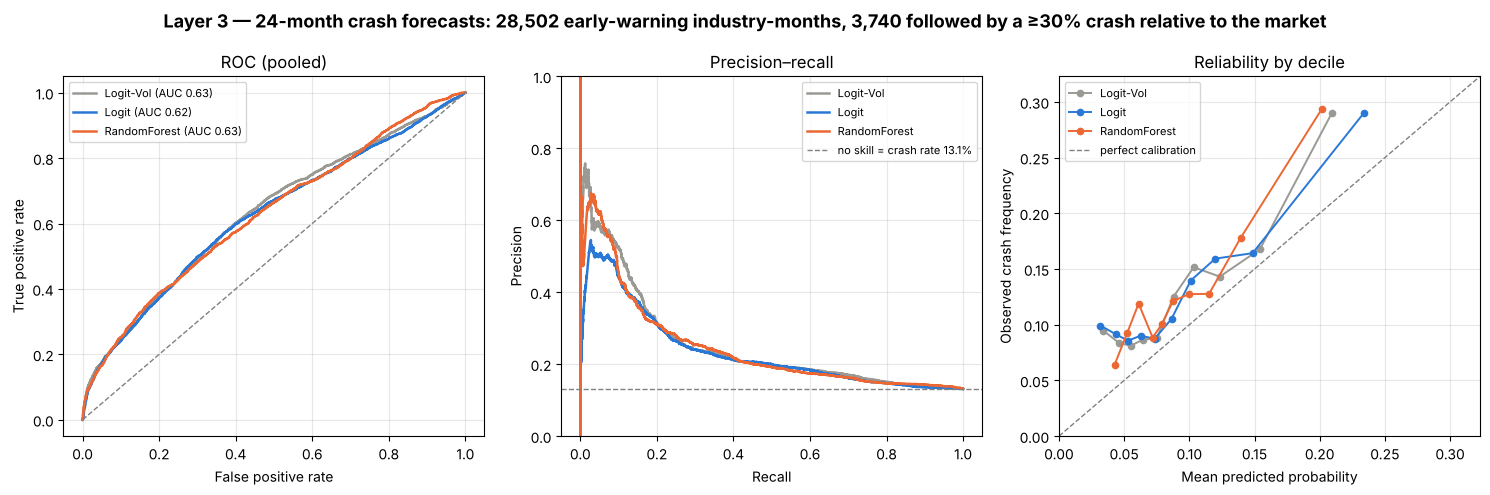

In [30]:
ew = EW[MAIN_H].dropna(subset=["y"] + MODELS)
y = ew["y"].values.astype(int)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(f"Layer 3 — {MAIN_H}-month crash forecasts: {len(ew):,} early-warning industry-months, "
             f"{y.sum():,} followed by a ≥{REL_DD:.0%} crash relative to the market", fontsize=13, fontweight="bold")
lim = 0
for m in MODELS:
    fpr, tpr, _ = roc_curve(y, ew[m])
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[m], lw=1.8, label=f"{m} (AUC {roc_auc_score(y, ew[m]):.2f})")
    pr, rc, _ = precision_recall_curve(y, ew[m])
    axes[1].plot(rc, pr, color=MODEL_COLORS[m], lw=1.8, label=m)
    rel = ew.groupby(pd.qcut(ew[m].rank(method="first"), 10, labels=False)).agg(p=(m, "mean"), obs=("y", "mean"))
    axes[2].plot(rel["p"], rel["obs"], "o-", color=MODEL_COLORS[m], ms=4.5, lw=1.4, label=m)
    lim = max(lim, rel.max().max() * 1.1)
axes[0].plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
axes[1].axhline(y.mean(), color="gray", ls="--", lw=1, label=f"no skill = crash rate {y.mean():.1%}")
axes[2].plot([0, lim], [0, lim], color="gray", ls="--", lw=1, label="perfect calibration")
axes[0].set(title="ROC (pooled)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Precision–recall", xlabel="Recall", ylabel="Precision", ylim=(0, 1))
axes[2].set(title="Reliability by decile", xlabel="Mean predicted probability", ylabel="Observed crash frequency",
            xlim=(0, lim), ylim=(0, lim))
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
save(fig, f"layer3_roc_pr_reliability_{MAIN_H}m")

## 6.4 Bubble detector or volatility ranker?
* **Purpose:** Test whether the full models add anything beyond "volatile industries fall further".
* **Method:** Three checks at 24 months. (1) The full models are compared with the volatility-only Logit on identical rows, for the headline label and for the absolute label. A difference whose interval contains 0 is no evidence of added skill. (2) Skill after removing volatility: industries are split each month into three volatility groups (`Vol6_R`), and XS-AUC is computed inside each group. If the models only rank volatility, XS-AUC inside a group falls towards 0.5.

In [31]:
vol_rows = []
for label, df in [(f"Relative crash (>= {REL_DD:.0%} vs market)", EW[MAIN_H]), (f"Absolute crash (>= {ABS_DD:.0%})", EW_ABS)]:
    res = evaluate(df, MODELS)
    for m in MODELS:
        row = {"Label": label, "Model": m, "Crash rate": res.loc[m, "Crash rate"],
               **res.loc[m, ["XS-AUC", "Time-AUC", "AUC", "BSS"]].to_dict()}
        if m != VOL_MODEL:
            d = paired_diff(df, m, VOL_MODEL)
            row.update({"ΔXS-AUC vs Logit-Vol": d["ΔXS-AUC"], "Δ lo": d["ΔXS-AUC lo"], "Δ hi": d["ΔXS-AUC hi"]})
        vol_rows.append(row)
vol_test = pd.DataFrame(vol_rows).set_index(["Label", "Model"])

vol6_r = panel["Vol6_R"].reindex(EW[MAIN_H].index)
rows = []
for name, sel in {"Low volatility third": vol6_r <= 1 / 3, "Middle third": (vol6_r > 1 / 3) & (vol6_r <= 2 / 3), "High volatility third": vol6_r > 2 / 3}.items():
    res = evaluate(EW[MAIN_H][sel], MODELS)
    for m in MODELS:
        rows.append({"Volatility group": name, "Model": m, **res.loc[m, ["N", "Crash rate", "XS-AUC", "XS-AUC lo", "XS-AUC hi"]].to_dict()})
within_vol = pd.DataFrame(rows).set_index(["Volatility group", "Model"]).astype({"N": int})
display(vol_test.round(3), within_vol.round(3))

Crash rate  XS-AUC  Time-AUC    AUC    BSS  ΔXS-AUC vs Logit-Vol   Δ lo   Δ hi
Label                             Model                                                                                       
Relative crash (>= 30% vs market) Logit-Vol          0.131   0.703     0.502  0.631  0.035                   NaN    NaN    NaN
                                  Logit              0.131   0.678     0.526  0.624  0.036                -0.025 -0.044  0.001
                                  RandomForest       0.131   0.710     0.516  0.628  0.036                 0.007 -0.017  0.040
Absolute crash (>= 40%)           Logit-Vol          0.089   0.760     0.315  0.587  0.022                   NaN    NaN    NaN
                                  Logit              0.089   0.737     0.456  0.595  0.034                -0.023 -0.044  0.002
                                  RandomForest       0.089   0.735     0.319  0.551  0.021                -0.024 -0.045  0.001

N  Crash rate  XS-AUC  XS-AUC lo  XS-AUC hi
Volatility group      Model                                                       
Low volatility third  Logit-Vol     9869       0.082   0.591      0.517      0.684
                      Logit         9869       0.082   0.553      0.479      0.644
                      RandomForest  9869       0.082   0.606      0.550      0.669
Middle third          Logit-Vol     9735       0.105   0.558      0.490      0.622
                      Logit         9735       0.105   0.528      0.472      0.596
                      RandomForest  9735       0.105   0.596      0.546      0.658
High volatility third Logit-Vol     8898       0.214   0.677      0.635      0.715
                      Logit         8898       0.214   0.637      0.603      0.686
                      RandomForest  8898       0.214   0.670      0.628      0.712

## 6.5 Which run-ups crash? (sub-samples of Greenwood, Shleifer & You)
* **Purpose:** Ask the question an investor faces during a boom: among industries that have already risen, which ones crash?
* **Method:** The 24-month scores are recomputed inside three sub-samples: positive 24-month return, top quintile of market-adjusted return, and the strict run-up definition (≥100% in 2 years). The strict sample is small, so its intervals are wide. It is also rare in training (see 4.4), and the Random Forest needs 300 rows per leaf, so the models cannot learn a separate pattern for run-ups. An AUC below 0.5 here means the models rank run-ups in the wrong order, and their forecasts for industries in a strict run-up should not be trusted.

In [32]:
SUBSETS = {"All early-warning months": lambda d: d["y"].notna(),
           "24M return > 0":           lambda d: d["R24"] > 0,
           "Net24 in the top quintile": lambda d: d["Net24_R"] >= 0.8,
           "Strict run-up (RunUp = 1)": lambda d: d["RunUp"] == 1}
rows = []
for name, rule in SUBSETS.items():
    sub = EW[MAIN_H][rule(EW[MAIN_H])]
    res = evaluate(sub, MODELS)
    for m in MODELS:
        rows.append({"Sub-sample": name, "Model": m, **res.loc[m, ["N", "Crash rate", "XS-AUC", "XS-AUC lo", "XS-AUC hi", "AUC", "AUC lo", "AUC hi"]].to_dict()})
gsy_table = pd.DataFrame(rows).set_index(["Sub-sample", "Model"]).astype({"N": int})
gsy_table.round(3)

N  Crash rate  XS-AUC  XS-AUC lo  XS-AUC hi    AUC  AUC lo  AUC hi
Sub-sample                Model                                                                               
All early-warning months  Logit-Vol     28502       0.131   0.703      0.666      0.742  0.631   0.590   0.700
                          Logit         28502       0.131   0.678      0.645      0.724  0.624   0.584   0.695
                          RandomForest  28502       0.131   0.710      0.682      0.742  0.628   0.579   0.702
24M return > 0            Logit-Vol     24092       0.130   0.705      0.661      0.750  0.630   0.576   0.700
                          Logit         24092       0.130   0.684      0.644      0.732  0.626   0.574   0.700
                          RandomForest  24092       0.130   0.709      0.671      0.749  0.627   0.567   0.700
Net24 in the top quintile Logit-Vol      6497       0.173   0.668      0.600      0.732  0.662   0.605   0.717
                          Logit          6497       0.173   0.642      0.575      0.697  0.663   0.610   0.713
                          RandomForest   6497       0.173   0.662      0.601      0.712  0.639   0.578   0.706
Strict run-up (RunUp = 1) Logit-Vol       272       0.577   0.649      0.378      1.000  0.535   0.271   0.723
                          Logit           272       0.577   0.412      0.033      1.000  0.311   0.145   0.457
                          RandomForest    272       0.577   0.596      0.357      1.000  0.559   0.251   0.797

## 6.6 Alerts against a matched random control
* **Purpose:** Rule out that an alert is only a momentum signal in disguise (Zhao & Sornette).
* **Method:** Alerted industry-months are compared with non-alerted ones that looked similar. Two matchings are used: on the 24-month return only (20 bins), and on the 24-month return and volatility together (5 × 5 bins). The second one asks whether an alert says more than "this industry is volatile". The control crash rate is the average over the bins of the alerted rows; alerted rows whose bin has no control are left out. The interval comes from the month-block bootstrap.

In [33]:
def matched_control(df, model, with_vol):
    d = df.join(panel["Vol6_R"]).dropna(subset=["y", "R24", "Vol6_R", model]).sort_index()
    d["alert"] = top_k_alert(d, model)
    if with_vol:
        d["bin"] = 5 * pd.qcut(d["R24"], 5, labels=False) + pd.cut(d["Vol6_R"], 5, labels=False)
    else:
        d["bin"] = pd.qcut(d["R24"], 20, labels=False, duplicates="drop")
    codes, months = pd.factorize(d.index.get_level_values("Date"))
    rows_of = [np.flatnonzero(codes == k) for k in range(len(months))]
    y, a, b = d["y"].values, d["alert"].values, d["bin"].values
    def calc(pos):
        ix = np.concatenate([rows_of[k] for k in pos])
        yy, aa, bb = y[ix], a[ix], b[ix]
        ctrl = pd.Series(yy[~aa]).groupby(bb[~aa]).mean().reindex(bb[aa]).values
        has = np.isfinite(ctrl)
        return yy[aa][has].mean(), ctrl[has].mean(), yy[aa][has].mean() - ctrl[has].mean()
    point = calc(np.arange(len(months)))
    lo, hi = np.nanpercentile([calc(pos)[2] for pos in block_positions(len(months))], [2.5, 97.5])
    return {"Alerted rows": int(a.sum()), "Crash rate | alert": point[0], "Matched control": point[1],
            "Difference": point[2], "Diff lo": lo, "Diff hi": hi, "All rows": y.mean()}

control_table = pd.DataFrame({(match, m): matched_control(EW[MAIN_H], m, with_vol)
                              for match, with_vol in [("24M return", False), ("24M return and volatility", True)] for m in MODELS}).T
control_table = control_table.astype({"Alerted rows": int}).rename_axis(["Matched on", "Model"])
control_table.round(3)

Alerted rows  Crash rate | alert  Matched control  Difference  Diff lo  Diff hi  All rows
Matched on                Model                                                                                                  
24M return                Logit-Vol             3859               0.282            0.120       0.162    0.108    0.211     0.131
                          Logit                 3859               0.266            0.130       0.136    0.076    0.189     0.131
                          RandomForest          3859               0.271            0.134       0.137    0.078    0.191     0.131
24M return and volatility Logit-Vol             3859               0.282            0.161       0.122    0.067    0.168     0.131
                          Logit                 3859               0.266            0.178       0.087    0.041    0.132     0.131
                          RandomForest          3859               0.271            0.174       0.097    0.053    0.142     0.131

## 6.7 Ablation: do Layer 1, Layer 2 and own-history features add skill?
* **Purpose:** Test whether the bubble signals (GSADF strength, small-firm tilt, volatility rising in a run-up), the HMM regime and the own-history features improve the forecasts. The own-history group is the one expected to help the timing dimension (Time-AUC).
* **Method:** Each variant is compared with the `Main` feature set on identical rows at 24 months. Many comparisons are made, so p-values are adjusted with the Benjamini–Hochberg false discovery rate; `Significant (FDR 10%)` is the column to read.

In [34]:
ew_abl = early_warning(ABL)
rows = []
for fam in ["Logit", "RF"]:
    for name in list(ABL_SETS)[1:]:
        d = paired_diff(ew_abl, f"{fam} | {name}", f"{fam} | Main")
        rows.append({"Model": fam, "Variant vs Main": name, **d})
abl_tests = pd.DataFrame(rows).set_index(["Model", "Variant vs Main"])
p_cols = ["p XS-AUC", "p Time-AUC", "p AUC", "p BSS"]
p_adj = multipletests(abl_tests[p_cols].values.ravel(), alpha=0.10, method="fdr_bh")[1].reshape(abl_tests[p_cols].shape)
abl_tests["Significant (FDR 10%)"] = [", ".join(c[2:] for c, q in zip(p_cols, row) if q < 0.10) or "none" for row in p_adj]
abl_scores = evaluate(ew_abl, list(ABL_SPECS))[["N", "XS-AUC", "Time-AUC", "AUC", "BSS"]]
display(abl_scores.round(3),
        abl_tests[["ΔXS-AUC", "ΔXS-AUC lo", "ΔXS-AUC hi", "ΔTime-AUC", "ΔTime-AUC lo", "ΔTime-AUC hi",
                   "ΔAUC", "ΔAUC lo", "ΔAUC hi", "ΔBSS", "ΔBSS lo", "ΔBSS hi", "Significant (FDR 10%)"]].round(3))

,N,XS-AUC,Time-AUC,AUC,BSS
Logit | Main,28138,0.678,0.524,0.617,0.031
Logit | Main + bubble signals,28138,0.680,0.531,0.620,0.029
Logit | Main + HMM regime,28138,0.677,0.509,0.610,0.029
Logit | Main + own history,28138,0.666,0.508,0.612,0.002
Logit | Main + all,28138,0.668,0.501,0.606,-0.002
RF | Main,28138,0.699,0.515,0.620,0.035
RF | Main + bubble signals,28138,0.704,0.514,0.625,0.037
RF | Main + HMM regime,28138,0.698,0.507,0.616,0.035
RF | Main + own history,28138,0.692,0.508,0.619,0.035
RF | Main + all,28138,0.696,0.502,0.617,0.035


ΔXS-AUC  ΔXS-AUC lo  ΔXS-AUC hi  ΔTime-AUC  ΔTime-AUC lo  ΔTime-AUC hi   ΔAUC  ΔAUC lo  ΔAUC hi   ΔBSS  ΔBSS lo  ΔBSS hi Significant (FDR 10%)
Model Variant vs Main                                                                                                                                                      
Logit Main + bubble signals    0.003      -0.008       0.014      0.007        -0.000         0.020  0.003   -0.007    0.011 -0.002   -0.008    0.003                  none
      Main + HMM regime       -0.001      -0.005       0.002     -0.015        -0.042         0.010 -0.007   -0.016    0.000 -0.003   -0.011    0.003                  none
      Main + own history      -0.012      -0.023      -0.000     -0.016        -0.071         0.036 -0.005   -0.027    0.017 -0.029   -0.086    0.001                  none
      Main + all              -0.010      -0.022       0.003     -0.023        -0.076         0.028 -0.011   -0.033    0.013 -0.033   -0.095   -0.000                  none
RF    Main + bubble signals    0.004      -0.004       0.013     -0.001        -0.006         0.004  0.005   -0.003    0.013  0.002   -0.001    0.006                  none
      Main + HMM regime       -0.001      -0.006       0.004     -0.008        -0.031         0.014 -0.004   -0.012    0.004 -0.000   -0.004    0.003                  none
      Main + own history      -0.007      -0.017      -0.000     -0.007        -0.035         0.020 -0.001   -0.010    0.007  0.000   -0.002    0.003                  none
      Main + all              -0.003      -0.016       0.008     -0.013        -0.044         0.021 -0.003   -0.014    0.009 -0.000   -0.005    0.004                  none

# Part 7 — Explainability

## 7.1 What drives the Random Forest forecast?
* **Purpose:** Show which inputs the main model relies on before four different crises.
* **Method:** SHAP values of the model fitted before each crisis, over all industries not already falling in that year. Values are shown as a share of mean |SHAP|, by feature and by feature group. An assert checks SHAP additivity. SHAP describes how the model uses its inputs; it is not a causal statement, and correlated features share credit.

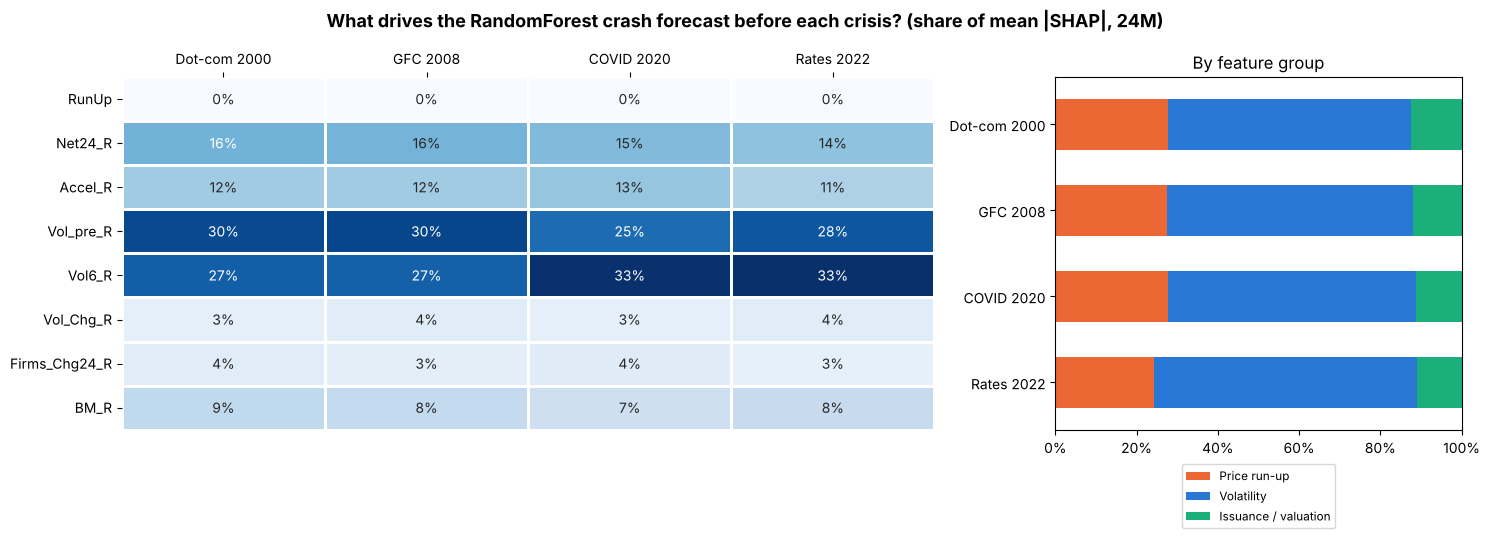

,Dot-com 2000,GFC 2008,COVID 2020,Rates 2022
Price run-up,0.278,0.276,0.278,0.243
Volatility,0.597,0.605,0.611,0.646
Issuance / valuation,0.125,0.119,0.112,0.111


In [35]:
SHAP_SHARE = {}
for crisis, year in EXPLAIN_YEARS.items():
    model = FITTED[(year, MAIN_MODEL)]
    rows = panel[(panel["Year"] == year) & ~panel["Masked"]]
    X = model["clip"].transform(rows[FEATS_MAIN])
    expl = shap.TreeExplainer(model["clf"])
    sv = expl.shap_values(X)
    sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)      # class 1 = crash
    gap = np.abs(np.atleast_1d(expl.expected_value)[-1] + sv.sum(axis=1) - model["clf"].predict_proba(X)[:, 1]).max()
    assert gap < 1e-3, f"SHAP additivity failed for {crisis}"
    SHAP_SHARE[crisis] = pd.Series(np.abs(sv).mean(axis=0), index=FEATS_MAIN)
shap_table = pd.DataFrame(SHAP_SHARE).reindex([f for g in FEAT_GROUP.values() for f in g])
shap_table = shap_table / shap_table.sum()
shap_group = pd.DataFrame({g: shap_table.loc[f].sum() for g, f in FEAT_GROUP.items()}).T

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [3, 1.5]})
fig.suptitle(f"What drives the {MAIN_MODEL} crash forecast before each crisis? (share of mean |SHAP|, {MAIN_H}M)",
             fontsize=13, fontweight="bold")
sns.heatmap(shap_table, annot=True, fmt=".0%", cmap="Blues", vmin=0, cbar=False, linewidths=1, ax=axes[0])
axes[0].xaxis.tick_top()
shap_group.T.plot.barh(stacked=True, ax=axes[1], width=0.6, color=["#eb6834", "#2a78d6", "#1baf7a"])
axes[1].invert_yaxis()
axes[1].set(title="By feature group", xlim=(0, 1))
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=8.5)
plt.tight_layout()
save(fig, "layer3_shap_by_crisis")
shap_group.round(3)

# Part 8 — From industries to the market

## 8.1 Crash-risk breadth
* **Purpose:** Summarise 48 industry probabilities into a few market-level numbers.
* **Method:** Among industries not already falling: the cap-weighted and equal-weighted mean P(crash), the number of industries with P ≥ 2× the base rate, and the number flagged by the GSADF test. Counting industries that signal at the same time follows Zhao & Sornette. Breadth is a summary of industry risk, not the probability of a market crash.

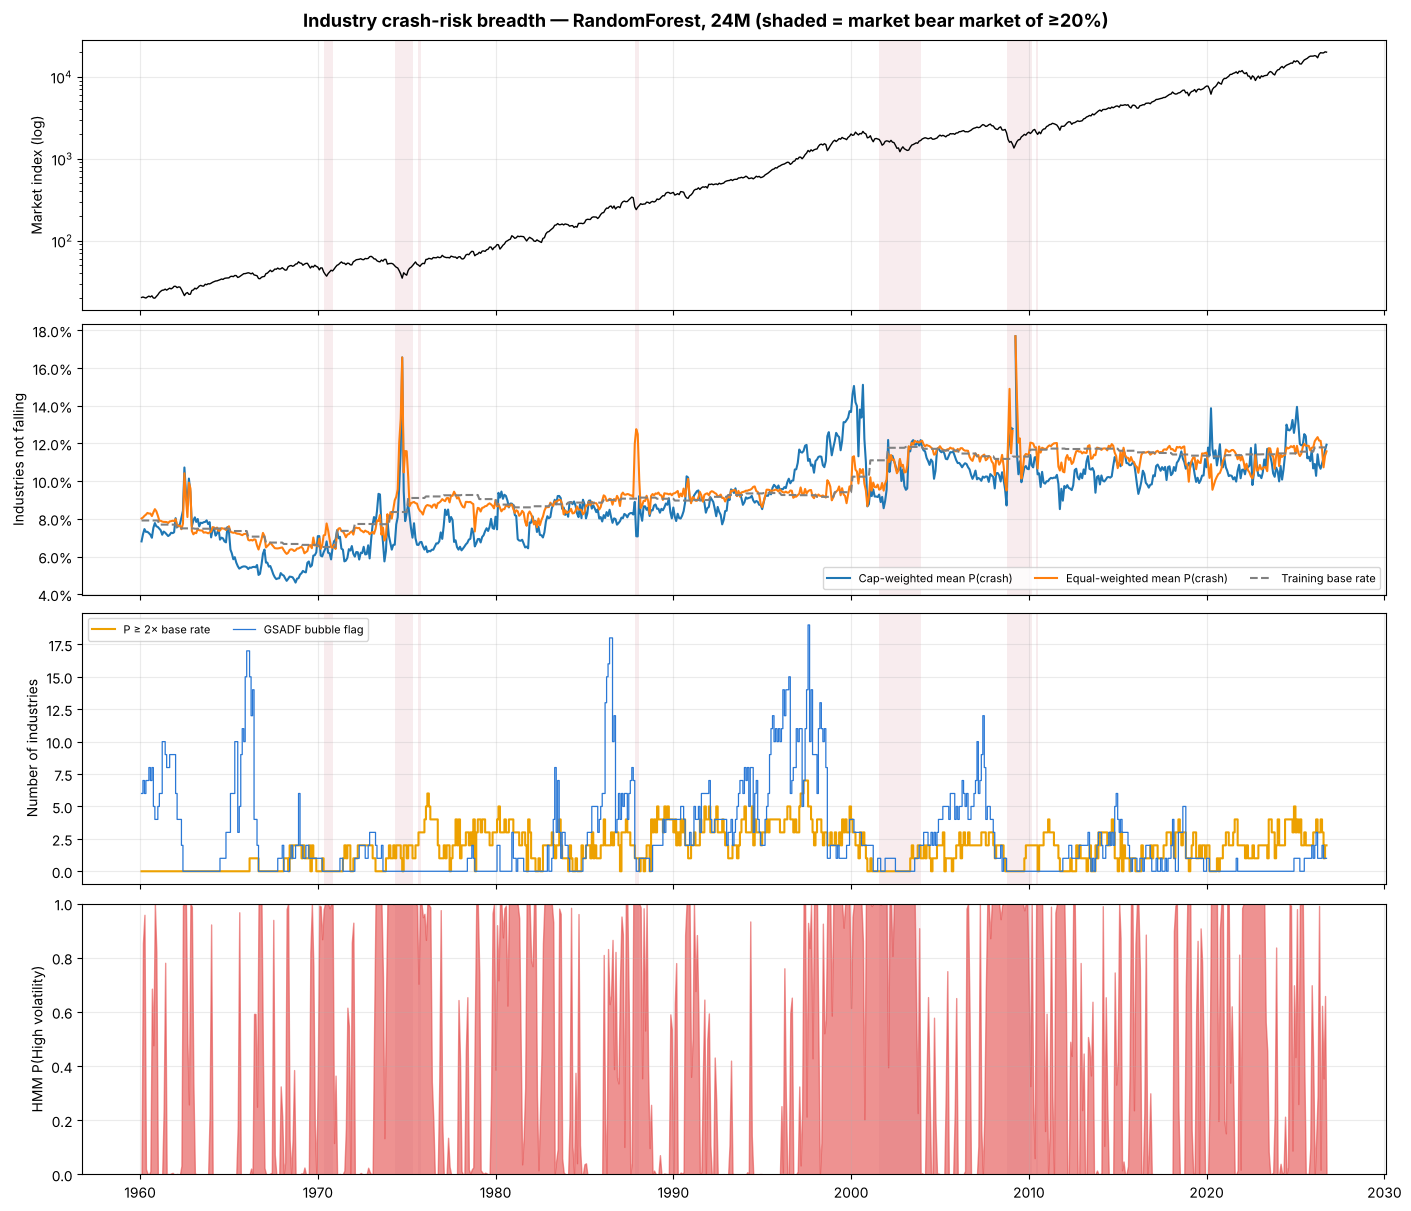

In [36]:
B = PRED[MAIN_H].copy()
assert B[MAIN_MODEL].notna().all() and (B["MCap"] > 0).all()
alive = ~B["Masked"]                                                # industry not already falling
B["w"] = B["MCap"] / B.groupby(level="Date")["MCap"].transform("sum")
B["Alert"] = top_k_alert(B, MAIN_MODEL)
by_date = lambda s: s.groupby(level="Date")
w_alive = B["w"].where(alive, 0.0)
breadth = pd.DataFrame({
    "CW mean P":       by_date(w_alive * B[MAIN_MODEL]).sum() / by_date(w_alive).sum(),
    "EW mean P":       by_date(B[MAIN_MODEL].where(alive)).mean(),
    "Base rate":       by_date(B["Base rate"]).first(),
    "N high-risk":     by_date((B[MAIN_MODEL] >= ALERT_MULT * B["Base rate"]) & alive).sum(),
    "N GSADF flag":    by_date(B["PSY_Bubble"].eq(1)).sum(),
    "GSADF share":     by_date(B["PSY_Bubble"].eq(1)).mean(),
    "Already falling": by_date(~alive).mean(),
    "N industries":    by_date(B["w"]).size()})
bear = ((mkt_m / mkt_m.cummax() - 1) <= -BEAR_DD).reindex(breadth.index, method="ffill")
p_highvol = regime_m["High volatility"].reindex(breadth.index)

fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True, constrained_layout=True)
fig.suptitle(f"Industry crash-risk breadth — {MAIN_MODEL}, {MAIN_H}M (shaded = market bear market of ≥{BEAR_DD:.0%})",
             fontsize=13, fontweight="bold")
axes[0].plot(mkt_m.reindex(breadth.index, method="ffill"), color="black", lw=1)
axes[0].set(yscale="log", ylabel="Market index (log)")
axes[1].plot(breadth["CW mean P"], label="Cap-weighted mean P(crash)")
axes[1].plot(breadth["EW mean P"], label="Equal-weighted mean P(crash)")
axes[1].plot(breadth["Base rate"], color="gray", ls="--", label="Training base rate")
axes[1].set(ylabel="Industries not falling")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1))
axes[2].step(breadth.index, breadth["N high-risk"], where="post", color="#eda100", label=f"P ≥ {ALERT_MULT:g}× base rate")
axes[2].step(breadth.index, breadth["N GSADF flag"], where="post", color="#2a78d6", lw=0.9, label="GSADF bubble flag")
axes[2].set(ylabel="Number of industries")
axes[3].fill_between(p_highvol.index, 0, p_highvol.values, color=REGIME_COLORS["High volatility"], alpha=0.6)
axes[3].set(ylim=(0, 1), ylabel="HMM P(High volatility)")
for ax in axes:
    ax.fill_between(bear.index, 0, 1, where=bear.values, step="post", color="#cc6677", alpha=0.12, lw=0,
                    transform=ax.get_xaxis_transform())
    ax.grid(True, alpha=0.25)
for ax in axes[1:3]:
    ax.legend(loc="lower right" if ax is axes[1] else "upper left", fontsize=8, ncol=3)
save(fig, "market_breadth")

## 8.2 Case study: breadth before every bear market
* **Purpose:** Look at what the breadth measures said 6 months before each market peak since 1960.
* **Method:** A bear market is a fall of at least 20% in the month-end index; it ends when the index regains its old peak. Peaks are identified in hindsight, so this is a descriptive case study and not a test of early warning. `Percentile` is the rank of the equal-weighted mean P within the history available at that date. The mean P follows the training base rate, which drifts over the decades, so a high percentile mostly reflects that drift; compare `EW mean P` with `Base rate` in the same row to see whether breadth was unusually high before a peak.

In [37]:
BEARS, peak_v, peak_d, trough = [], mkt_m.iloc[0], mkt_m.index[0], None
for d, v in mkt_m.dropna().items():
    if trough is None:
        if v > peak_v:
            peak_v, peak_d = v, d
        elif v / peak_v - 1 <= -BEAR_DD:
            trough = (d, v)
    else:
        trough = min(trough, (d, v), key=lambda t: t[1])
        if v >= peak_v:
            BEARS.append((peak_d, trough[0], trough[1] / peak_v - 1))
            peak_v, peak_d, trough = v, d, None
if trough is not None:
    BEARS.append((peak_d, trough[0], trough[1] / peak_v - 1))
BEARS = [b for b in BEARS if b[0] >= breadth.index[0] + pd.DateOffset(months=12)]

def asof_value(s, date, months=6):
    s = s.loc[:date - pd.DateOffset(months=months)].dropna()
    return s.iloc[-1], (s <= s.iloc[-1]).mean()                     # value and its percentile in the history so far

rows = []
for peak, trough_d, dd in BEARS:
    snap = B.xs(breadth.loc[:peak - pd.DateOffset(months=6)].index[-1], level="Date")
    top = snap[~snap["Masked"]].nlargest(3, MAIN_MODEL)
    ew_p, ew_pct = asof_value(breadth["EW mean P"], peak)
    rows.append({"Peak": f"{peak:%Y-%m}", "Trough": f"{trough_d:%Y-%m}", "Max drawdown": dd,
                 "EW mean P": ew_p, "Percentile": ew_pct, "Base rate": asof_value(breadth["Base rate"], peak)[0],
                 "N high-risk": asof_value(breadth["N high-risk"], peak)[0],
                 "N GSADF flag": asof_value(breadth["N GSADF flag"], peak)[0],
                 "HMM P(High vol)": asof_value(p_highvol, peak)[0],
                 "Riskiest industries": ", ".join(f"{i} ({p:.0%})" for i, p in top[MAIN_MODEL].items())})
bear_table = pd.DataFrame(rows).set_index("Peak")
bear_table.round(3).astype({"N high-risk": int, "N GSADF flag": int})

,Trough,Max drawdown,EW mean P,Percentile,Base rate,N high-risk,N GSADF flag,HMM P(High vol),Riskiest industries
Peak,,,,,,,,,
1961-12,1962-06,-0.230,0.078,0.056,0.077,0,8,0.000,"Fun (13%), Hshld (11%), Ships (11%)"
1968-11,1970-06,-0.333,0.062,0.020,0.067,0,0,0.999,"RlEst (13%), Meals (13%), Fun (12%)"
1972-12,1974-09,-0.459,0.074,0.600,0.077,2,2,0.002,"Fun (20%), Meals (17%), Gold (13%)"
1987-08,1987-11,-0.297,0.094,0.963,0.091,3,5,0.886,"Gold (20%), Toys (19%), Beer (18%)"
2000-08,2002-09,-0.435,0.113,0.983,0.102,3,3,1.000,"Chips (25%), Hardw (23%), Softw (22%)"
2007-10,2009-02,-0.490,0.113,0.901,0.113,3,9,0.164,"Mines (27%), Coal (26%), Steel (25%)"
2019-12,2020-03,-0.204,0.111,0.759,0.114,1,1,0.862,"Mines (24%), Toys (22%), Fun (19%)"
2021-12,2022-09,-0.245,0.117,0.879,0.114,3,0,0.331,"Toys (30%), Steel (28%), Autos (27%)"


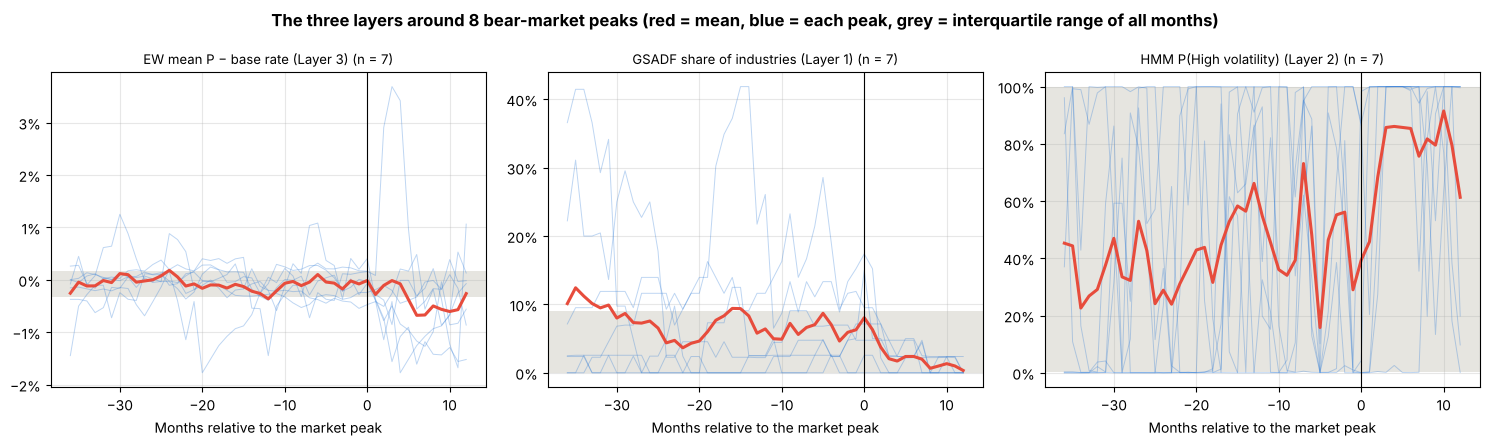

In [38]:
K_BEFORE, K_AFTER = 36, 12
SERIES = {"EW mean P − base rate (Layer 3)": breadth["EW mean P"] - breadth["Base rate"],
          "GSADF share of industries (Layer 1)": breadth["GSADF share"],
          "HMM P(High volatility) (Layer 2)": p_highvol}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle(f"The three layers around {len(BEARS)} bear-market peaks (red = mean, blue = each peak, grey = interquartile range of all months)",
             fontsize=12, fontweight="bold")
for ax, (name, s) in zip(axes, SERIES.items()):
    s = s.dropna()
    pos = [s.index.searchsorted(p) for p, _, _ in BEARS]
    paths = pd.DataFrame({p: s.iloc[p - K_BEFORE:p + K_AFTER + 1].values for p in pos if p - K_BEFORE >= 0 and p + K_AFTER < len(s)},
                         index=np.arange(-K_BEFORE, K_AFTER + 1))
    ax.axhspan(*s.quantile([0.25, 0.75]), color="#e6e5e0", lw=0)
    ax.plot(paths, color="#2a78d6", lw=0.7, alpha=0.3)
    ax.plot(paths.mean(axis=1), color="#e74c3c", lw=2.2)
    ax.axvline(0, color="black", lw=0.8)
    ax.set(xlabel="Months relative to the market peak")
    ax.set_title(f"{name} (n = {paths.shape[1]})", fontsize=9.5)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
    ax.grid(True, alpha=0.3)
plt.tight_layout()
save(fig, "market_event_study_peaks")

## 8.3 Did risk rise before the 2020 and 2022 drawdowns?
* **Purpose:** Check the two most recent stress episodes, which the model never saw in training at the time.
* **Method:** Cap-weighted mean P(crash) against the training base rate. The red line is the first day the index is 10% below a peak inside the window. Two episodes are an illustration, not a test.

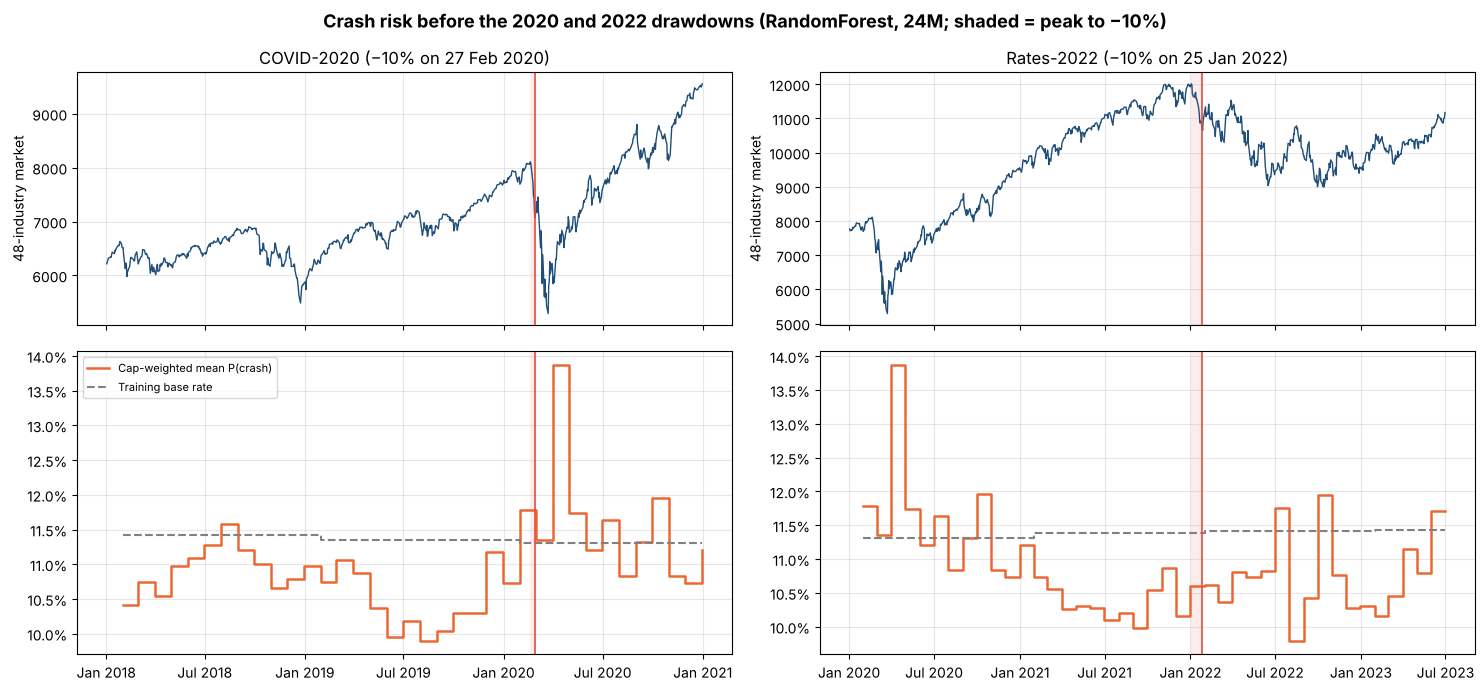

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(15, 7), sharex="col", gridspec_kw={"height_ratios": [1, 1.2]})
fig.suptitle(f"Crash risk before the 2020 and 2022 drawdowns ({MAIN_MODEL}, {MAIN_H}M; shaded = peak to −10%)",
             fontsize=13, fontweight="bold")
for col, (win, (a, b)) in enumerate(TEST_WINDOWS.items()):
    s = mkt_daily.loc[:b]
    peak_date = s.index.to_series().where(s >= s.cummax()).ffill()
    hit = ((s / s.cummax() - 1 <= -0.10) & (peak_date >= pd.Timestamp(a))).loc[a:]
    onset = hit[hit].index[0]
    start = pd.Timestamp(a) - pd.DateOffset(months=12)
    axes[0, col].plot(mkt_daily.loc[start:b], color="#1f4e79", lw=1)
    axes[0, col].set(title=f"{win} (−10% on {onset:%d %b %Y})", ylabel=MKT_NAME)
    axes[1, col].step(breadth.loc[start:b].index, breadth.loc[start:b, "CW mean P"], where="post", color="#eb6834", lw=1.8,
                      label="Cap-weighted mean P(crash)")
    axes[1, col].step(breadth.loc[start:b].index, breadth.loc[start:b, "Base rate"], where="post", color="gray", ls="--",
                      label="Training base rate")
    axes[1, col].yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=1))
    axes[1, col].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    axes[1, col].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    for ax in axes[:, col]:
        ax.axvline(onset, color="#e74c3c", lw=1.2)
        ax.axvspan(peak_date[onset], onset, color="#e74c3c", alpha=0.1, lw=0)
        ax.grid(True, alpha=0.3)
axes[1, 0].legend(fontsize=8)
plt.tight_layout()
save(fig, "test_windows_2020_2022")

## 8.4 Two-stage model: separate "when" from "which industry"
* **Purpose:** Improve the probability level without touching the industry ranking.
* **Method:**
    * **Why:** the Layer 3 level follows the training base rate and carries no market-wide information (6.2). The two-stage model tests whether market-wide variables can set a better level. It counts as timing skill only if Stage 1 itself predicts the crash share out of sample (last table: correlation above 0 and R² above 0).
    * **Stage 1 (market level, "when"):** a Ridge regression predicts the share of industries that will crash within 24 months from market-wide variables only: GSADF breadth, CAPE percentile, credit spread, term spread, return dispersion and the HMM probability. Slow data enter with a publication lag. It is refitted every year with the same embargo and time decay as Layer 3.
    * **Stage 2 (industry level, "which"):** the Random Forest ranking of Part 5.
    * **Combination:** each month, the Stage 2 probabilities are rescaled so that their average equals the Stage 1 level. The ranking inside a month is unchanged; only the level moves.
    * Both are scored on the same rows from 1975.

In [40]:
def asof(s, lag, ffill):
    # value of month M becomes usable `lag` months later and is carried forward at most `ffill` months
    s = s.dropna()
    return s.reindex(pd.date_range(s.index[0], END, freq="ME")).shift(lag).ffill(limit=ffill).reindex(ret.index)

market = pd.DataFrame({
    "GSADF_Share":   ind_psy.mean(axis=1),
    "CAPE_Pctl":     asof(cape.expanding(min_periods=120).apply(lambda s: (s <= s[-1]).mean(), raw=True), CAPE_LAG, CAPE_FFILL),
    "Credit_Spread": asof(fred["BAA"] - fred["AAA"], FRED_LAG, FRED_FFILL),
    "Term_Spread":   asof(fred["GS10"] - fred["TB3MS"], FRED_LAG, FRED_FFILL),
    "Dispersion":    lag_return(ret, 12).std(axis=1),
    "HMM_HighVol":   regime_m["High volatility"].reindex(ret.index)})
MKT_FEATS = list(market.columns)
lab_rows = panel[~panel["Masked"]]
market["Crash share"] = lab_rows[f"Crash_{MAIN_H}"].groupby(level="Date").mean()   # realised share, known only at t + H

stage1 = pd.Series(np.nan, index=market.index, name="Stage 1 level")
for year in range(STAGE1_TEST_YEAR, market.index[-1].year + 1):
    fit_date = pd.Timestamp(f"{year - 1}-12-31")
    train = market.loc[:fit_date - pd.DateOffset(months=MAIN_H)].dropna()          # embargo
    test = market.loc[f"{year}", MKT_FEATS].dropna()
    w = 0.5 ** ((fit_date - train.index).days / 365.25 / HALF_LIFE)        # same half-life as Layer 3
    reg = Pipeline([("scale", StandardScaler()), ("reg", Ridge(alpha=1.0))])
    reg.fit(train[MKT_FEATS], train["Crash share"], reg__sample_weight=np.asarray(w))
    stage1.loc[test.index] = np.clip(reg.predict(test), 0.001, 0.999)

TS = PRED[MAIN_H].copy()
dates = TS.index.get_level_values("Date")
level = stage1.reindex(dates).values
mean_p = TS[MAIN_MODEL].where(~TS["Masked"]).groupby(level="Date").transform("mean").values
TS["Two-stage"] = np.clip(TS[MAIN_MODEL] * level / mean_p, 0, 1)
ew_ts = early_warning(TS[dates.year >= STAGE1_TEST_YEAR])
two_stage = evaluate(ew_ts, ["Base rate", MAIN_MODEL, "Two-stage"])
ts_diff = pd.Series(paired_diff(ew_ts, "Two-stage", MAIN_MODEL), name=f"Two-stage − {MAIN_MODEL}")

s1 = pd.concat([stage1, market["Crash share"], breadth["Base rate"]], axis=1).dropna()
stage1_skill = pd.Series({"Months": len(s1), "Correlation with realised crash share": s1["Stage 1 level"].corr(s1["Crash share"]),
                          "Out-of-sample R² vs base rate": 1 - ((s1["Stage 1 level"] - s1["Crash share"]) ** 2).sum()
                                                               / ((s1["Base rate"] - s1["Crash share"]) ** 2).sum()},
                         name="Stage 1").to_frame()
display(two_stage[["N", "Crash rate", "XS-AUC", "Time-AUC", "AUC", "AUC lo", "AUC hi", "BSS", "BSS lo", "BSS hi"]].round(3),
        ts_diff.to_frame().T[["ΔTime-AUC", "ΔTime-AUC lo", "ΔTime-AUC hi", "ΔAUC", "ΔAUC lo", "ΔAUC hi", "ΔBSS", "ΔBSS lo", "ΔBSS hi"]].round(3),
        stage1_skill.round(3))

,N,Crash rate,XS-AUC,Time-AUC,AUC,AUC lo,AUC hi,BSS,BSS lo,BSS hi
Base rate,22833,0.136,NaN,0.476,0.476,0.380,0.535,0.000,0.000,0.000
RandomForest,22833,0.136,0.701,0.505,0.613,0.538,0.705,0.035,0.018,0.064
Two-stage,22833,0.136,0.701,0.485,0.578,0.481,0.679,0.019,-0.018,0.058


,ΔTime-AUC,ΔTime-AUC lo,ΔTime-AUC hi,ΔAUC,ΔAUC lo,ΔAUC hi,ΔBSS,ΔBSS lo,ΔBSS hi
Two-stage − RandomForest,-0.02,-0.094,0.049,-0.034,-0.087,-0.002,-0.016,-0.051,0.006


,Stage 1
Months,596.000
Correlation with realised crash share,-0.080
Out-of-sample R² vs base rate,-0.121


## 8.5 Does industry crash risk predict the market?
* **Purpose:** Test whether breadth is useful for the overall equity exposure (Greenwood, Shleifer & You, Internet Appendix).
* **Method:** In-sample regression. The market excess return over the next 24 months is regressed on today's breadth measure, one at a time. The predictor is standardised, so the coefficient is the change in the 24-month log excess return for a one-standard-deviation rise. Standard errors are Newey–West with 24 lags because the 24-month windows overlap. A useful warning signal needs a **negative** coefficient, and the five measures should agree. A positive coefficient means risk looked high before good market returns, which is what a lagging level produces after a crash wave.

In [41]:
excess = np.log1p(mkt) - np.log1p(RF_M.reindex(mkt.index))
fwd = excess.rolling(MAIN_H, min_periods=MAIN_H).sum().shift(-MAIN_H)             # months t+1 ... t+24
rows = []
for name, x in {"EW mean P(crash)": breadth["EW mean P"], "CW mean P(crash)": breadth["CW mean P"],
                "N high-risk industries": breadth["N high-risk"], "GSADF share of industries": breadth["GSADF share"],
                "Stage 1 level": stage1}.items():
    d = pd.concat([fwd.rename("y"), ((x - x.mean()) / x.std()).rename("x")], axis=1).dropna()
    fit = sm.OLS(d["y"], sm.add_constant(d["x"])).fit(cov_type="HAC", cov_kwds={"maxlags": MAIN_H})
    rows.append({"Predictor (1 sd)": name, "Months": len(d), "Coefficient": fit.params["x"], "t (Newey-West)": fit.tvalues["x"],
                 "p-value": fit.pvalues["x"], "R²": fit.rsquared})
market_reg = pd.DataFrame(rows).set_index("Predictor (1 sd)")
market_reg.round(3)

,Months,Coefficient,t (Newey-West),p-value,R²
Predictor (1 sd),,,,,
EW mean P(crash),776,0.059,2.355,0.019,0.072
CW mean P(crash),776,0.045,1.345,0.179,0.042
N high-risk industries,777,-0.011,-0.488,0.625,0.002
GSADF share of industries,777,-0.012,-0.488,0.626,0.003
Stage 1 level,597,-0.045,-1.943,0.052,0.048


# Part 9 — Backtest: is the signal worth money?

## 9.1 Portfolio engine and performance metrics
* **Purpose:** Turn monthly target weights into net returns with one function.
* **Method:**
    * Weights are set at the end of month *t* from predictions that use data up to *t*, and earn the return of month *t+1*.
    * Weight not held in industries sits in T-bills.
    * Cost is 10 bps of traded value, measured against the weights after they drifted with the previous month's returns.
    * Monthly data: return × 12, volatility × √12, Sharpe from the excess return over the T-bill. Max drawdown uses the running peak of compounded wealth. CVaR 5% is the mean of the worst 5% of months, reported as a positive loss. Downside beta is the beta to the market in months when the market excess return is negative.

In [42]:
def run_portfolio(w, cost_bps=COST_BPS):
    r_next  = ret.shift(-1).reindex(index=w.index, columns=w.columns)              # return of month t+1
    rf_next = RF_M.shift(-1).reindex(w.index)
    keep = r_next.notna().any(axis=1) & rf_next.notna()
    Wt, R, F = w[keep].fillna(0.0).values, r_next[keep].fillna(0.0).values, rf_next[keep].values
    assert (Wt >= -1e-12).all() and (Wt.sum(axis=1) <= 1 + 1e-9).all(), "weights must be long-only and sum to at most 1"
    gross, turn, prev = np.zeros(len(Wt)), np.zeros(len(Wt)), np.zeros(Wt.shape[1])
    for t in range(len(Wt)):
        turn[t]  = np.abs(Wt[t] - prev).sum()                                      # trade at the end of month t
        gross[t] = Wt[t] @ R[t] + (1 - Wt[t].sum()) * F[t]
        prev = Wt[t] * (1 + R[t]) / (1 + gross[t])                                 # weights after drifting through t+1
    idx = w.index[keep] + pd.offsets.MonthEnd(1)                                   # month in which the return is earned
    return pd.DataFrame({"gross": gross, "cost": cost_bps / 1e4 * turn, "net": gross - cost_bps / 1e4 * turn,
                         "turnover": turn, "cash": 1 - Wt.sum(axis=1)}, index=idx)

def perf(r):
    r = r.dropna()
    rf, m_ex = RF_M.reindex(r.index), (mkt - RF_M.reindex(mkt.index)).reindex(r.index)
    cum = (1 + r).cumprod()
    cagr, vol = cum.iloc[-1] ** (12 / len(r)) - 1, r.std() * np.sqrt(12)
    mdd = (cum / cum.cummax().clip(lower=1.0) - 1).min()
    down = m_ex < 0
    return {"Ann. return": r.mean() * 12, "CAGR": cagr, "Ann. vol": vol, "Sharpe": (r - rf).mean() * 12 / vol,
            "Max drawdown": mdd, "Calmar": cagr / abs(mdd), "CVaR 5% (monthly)": -r[r <= r.quantile(0.05)].mean(),
            "Downside beta": np.cov((r - rf)[down], m_ex[down])[0, 1] / m_ex[down].var()}

def diff_ci(r, ctrl):
    d = (r - ctrl).dropna().values
    lo, hi = np.percentile([d[ix].mean() * 12 for ix in block_positions(len(d))], [2.5, 97.5])
    return {"Δ ann. return vs control": d.mean() * 12, "Δ lo": lo, "Δ hi": hi}

P_wide    = PRED[MAIN_H][MODELS].where(~PRED[MAIN_H]["Masked"]).unstack("Industry")   # P of industries not already falling
cap_wide  = PRED[MAIN_H]["MCap"].unstack("Industry")
BASE_W = {"Cap-weighted": cap_wide.div(cap_wide.sum(axis=1), axis=0),
          "Equal-weighted": cap_wide.notna().div(cap_wide.notna().sum(axis=1), axis=0)}

## 9.2 Value of the ranking: quintile long–short
* **Purpose:** Measure the economic value of the ranking directly, with more statistical power than removing a few industries.
* **Method:** Each month, hold the equal-weighted quintile with the lowest P(crash) and short the quintile with the highest. Returns are net of trading costs on both legs. Alpha comes from CAPM and Fama–French three-factor regressions with Newey–West standard errors (12 lags). The short leg is a measuring device only: shorting a bubble is risky and is not the recommended action. The volatility-only model is included to see how much of the spread is a low-volatility effect.

In [43]:
def quintile_ls(model):
    q = P_wide[model].rank(axis=1, pct=True)
    legs = [run_portfolio(sel.div(sel.sum(axis=1), axis=0).astype(float)) for sel in (q <= 0.2, q >= 0.8)]
    return (legs[0]["gross"] - legs[1]["gross"] - legs[0]["cost"] - legs[1]["cost"]).rename(model)

rows = {}
for m in MODELS:
    ls = quintile_ls(m)
    X = ff[["Mkt-RF", "SMB", "HML"]].reindex(ls.index)
    capm = sm.OLS(ls, sm.add_constant(X[["Mkt-RF"]]), missing="drop").fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    ff3  = sm.OLS(ls, sm.add_constant(X), missing="drop").fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    rows[m] = {"Months": len(ls), "Ann. return (x12)": ls.mean() * 12, "Ann. vol (x sqrt12)": ls.std() * np.sqrt(12),
               "CAPM alpha (ann.)": capm.params["const"] * 12, "t CAPM": capm.tvalues["const"], "Market beta": capm.params["Mkt-RF"],
               "FF3 alpha (ann.)": ff3.params["const"] * 12, "t FF3": ff3.tvalues["const"]}
ls_table = pd.DataFrame(rows).T.astype({"Months": int})
ls_table.round(3)

,Months,Ann. return (x12),Ann. vol (x sqrt12),CAPM alpha (ann.),t CAPM,Market beta,FF3 alpha (ann.),t FF3
Logit-Vol,800,-0.027,0.134,0.004,0.236,-0.433,-0.002,-0.090
Logit,800,-0.056,0.137,-0.027,-1.512,-0.406,-0.030,-1.689
RandomForest,800,-0.052,0.121,-0.035,-2.201,-0.236,-0.037,-2.303


## 9.3 Risk overlay: remove the five riskiest industries
* **Purpose:** Test the action an investor would actually take.
* **Method:** Each month the 5 industries with the highest P(crash) are removed from a cap-weighted or equal-weighted portfolio. The freed weight goes either to T-bills or pro rata to the remaining industries. Two controls isolate the effect of the signal:
    * **Control** — the same industries with no alerts.
    * **Exposure-matched control** — the control scaled down to the same average T-bill share, so that a lower drawdown cannot come from simply holding less equity.

In [44]:
def overlay_weights(base, model, to_cash):
    alert = P_wide[model].rank(axis=1, ascending=False, method="first") <= ALERT_K
    w = base.where(~alert, 0.0)
    return w if to_cash else w.div(w.sum(axis=1), axis=0)

BT, bt_rows = {}, []
for scheme, base in BASE_W.items():
    ctrl = run_portfolio(base)
    BT[(scheme, "Control")] = ctrl
    for model in [MAIN_MODEL, BENCH_MODEL]:
        BT[(scheme, f"{model}: top-{ALERT_K} to T-bills")]     = run_portfolio(overlay_weights(base, model, True))
        BT[(scheme, f"{model}: top-{ALERT_K} to other industries")] = run_portfolio(overlay_weights(base, model, False))
    cash = BT[(scheme, f"{MAIN_MODEL}: top-{ALERT_K} to T-bills")]["cash"].mean()
    BT[(scheme, "Exposure-matched control")] = run_portfolio(base * (1 - cash))
bt_common = sorted(set.intersection(*[set(v.index) for v in BT.values()]))
for (scheme, name), v in BT.items():
    r, ctrl = v["net"].reindex(bt_common), BT[(scheme, "Control")]["net"].reindex(bt_common)
    bt_rows.append({"Weighting": scheme, "Strategy": name, **perf(r), "Turnover (one-way, /yr)": v["turnover"].reindex(bt_common).mean() * 6,
                    "Avg. T-bill share": v["cash"].reindex(bt_common).mean(), **({} if name == "Control" else diff_ci(r, ctrl))})
BT_TABLE = pd.DataFrame(bt_rows).set_index(["Weighting", "Strategy"]).sort_index(level=0, sort_remaining=False)
print(f"Common sample: {bt_common[0]:%Y-%m} to {bt_common[-1]:%Y-%m} ({len(bt_common)} months), net of {COST_BPS} bps per unit traded")
BT_TABLE.round(3)

Common sample: 1960-02 to 2026-09 (800 months), net of 10 bps per unit traded


Ann. return   CAGR  Ann. vol  Sharpe  Max drawdown  Calmar  CVaR 5% (monthly)  Downside beta  Turnover (one-way, /yr)  Avg. T-bill share  Δ ann. return vs control   Δ lo   Δ hi
Weighting      Strategy                                                                                                                                                                                                                 
Cap-weighted   Control                                        0.115  0.108     0.153   0.472        -0.500   0.216              0.096          1.000                    0.255              0.000                       NaN    NaN    NaN
               RandomForest: top-5 to T-bills                 0.102  0.097     0.136   0.440        -0.466   0.209              0.085          0.880                    0.566              0.104                    -0.013 -0.021 -0.005
               RandomForest: top-5 to other industries        0.111  0.104     0.152   0.450        -0.515   0.202              0.096          0.993                    0.764              0.000                    -0.004 -0.010  0.002
               Logit: top-5 to T-bills                        0.105  0.100     0.138   0.453        -0.476   0.209              0.085          0.890                    0.486              0.086                    -0.010 -0.017 -0.002
               Logit: top-5 to other industries               0.111  0.104     0.152   0.452        -0.517   0.202              0.095          0.982                    0.632              0.000                    -0.004 -0.009  0.001
               Exposure-matched control                       0.107  0.103     0.137   0.472        -0.459   0.223              0.086          0.895                    0.229              0.104                    -0.008 -0.011 -0.004
Equal-weighted Control                                        0.121  0.112     0.168   0.467        -0.526   0.213              0.106          1.069                    0.216             -0.000                       NaN    NaN    NaN
               RandomForest: top-5 to T-bills                 0.108  0.102     0.147   0.444        -0.496   0.205              0.093          0.945                    0.539              0.121                    -0.013 -0.018 -0.007
               RandomForest: top-5 to other industries        0.117  0.108     0.167   0.444        -0.539   0.199              0.106          1.069                    0.615              0.000                    -0.004 -0.008 -0.001
               Logit: top-5 to T-bills                        0.107  0.100     0.147   0.436        -0.500   0.200              0.092          0.942                    0.510              0.121                    -0.014 -0.020 -0.009
               Logit: top-5 to other industries               0.115  0.106     0.166   0.436        -0.543   0.195              0.105          1.065                    0.583              0.000                    -0.006 -0.010 -0.002
               Exposure-matched control                       0.112  0.105     0.148   0.467        -0.476   0.221              0.092          0.940                    0.191              0.121                    -0.009 -0.014 -0.005

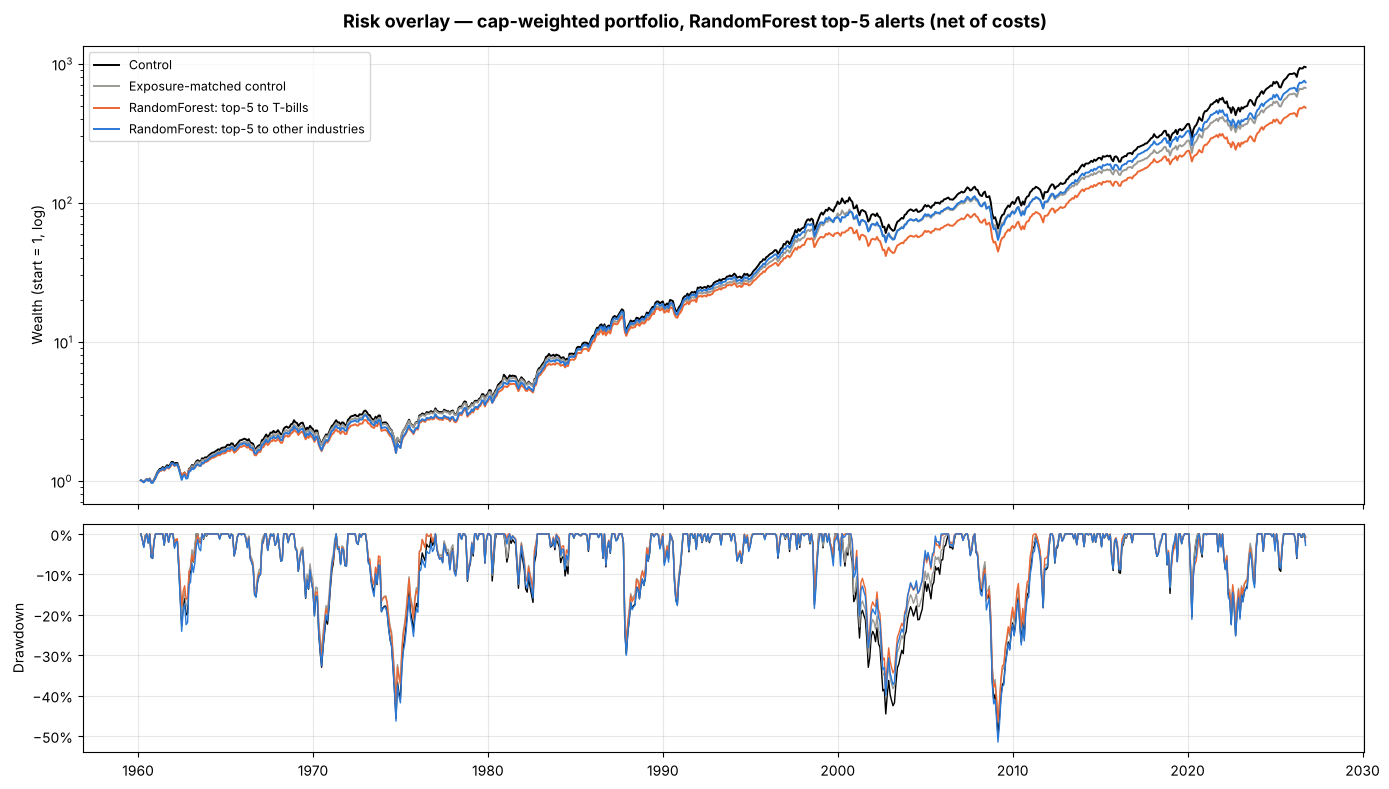

In [45]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
fig.suptitle(f"Risk overlay — cap-weighted portfolio, {MAIN_MODEL} top-{ALERT_K} alerts (net of costs)", fontsize=13, fontweight="bold")
LINES = {"Control": "black", "Exposure-matched control": "#9a9994",
         f"{MAIN_MODEL}: top-{ALERT_K} to T-bills": "#eb6834", f"{MAIN_MODEL}: top-{ALERT_K} to other industries": "#2a78d6"}
for name, c in LINES.items():
    cum = (1 + BT[("Cap-weighted", name)]["net"].reindex(bt_common)).cumprod()
    axes[0].plot(cum, color=c, lw=1.4, label=name)
    axes[1].plot(cum / cum.cummax() - 1, color=c, lw=1)
axes[0].set(yscale="log", ylabel="Wealth (start = 1, log)")
axes[0].legend(fontsize=9)
axes[1].set(ylabel="Drawdown")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
save(fig, "backtest_overlay")

# Part 10 — Decision view for the investor

## 10.1 Latest reading
* **Purpose:** Give the current state of the system in the form an investor would use each month.
* **Method:** The latest month's market-level numbers with their historical percentile, then the ten industries with the highest P(crash). `x base rate` is P divided by the training base rate. Outcomes for the last 24 months are not yet known, so these are forecasts, not verified results. Two cautions when reading the list:
    * `Strict run-up` = 1 marks industries inside the run-up definition, where the models ranked in the wrong order out of sample (6.5). A large gap between the Random Forest and the Logit for such an industry is a sign of that weakness, not of information.
    * `Largest industry weight` shows how concentrated the market is. When one industry holds a large share, every cap-weighted number (CW mean P, the cap-weighted overlay in 9.3) is close to a statement about that industry alone.

In [46]:
last = breadth.index[-1]
pct = lambda s: (s.dropna() <= s.loc[last]).mean()
latest = pd.DataFrame({"Value": breadth.loc[last, ["EW mean P", "CW mean P", "Base rate", "N high-risk", "N GSADF flag", "Already falling"]],
                       "Historical percentile": [pct(breadth[c]) for c in ["EW mean P", "CW mean P", "Base rate", "N high-risk", "N GSADF flag", "Already falling"]]})
latest.loc["Largest industry weight"] = [B["w"].xs(last, level="Date").max(), (by_date(B["w"]).max() <= B["w"].xs(last, level="Date").max()).mean()]
latest.loc["HMM P(High volatility)"] = [regime_m["High volatility"].iloc[-1], pct(regime_m["High volatility"])]
latest.loc["Stage 1 level (expected crash share)"] = [stage1.dropna().iloc[-1], (stage1.dropna() <= stage1.dropna().iloc[-1]).mean()]

now = B.xs(last, level="Date").join(panel.xs(last, level="Date")[["Net24", "DD12"]])
now["Sector"] = now.index.map(SECTOR_OF)
now["x base rate"] = now[MAIN_MODEL] / now["Base rate"]
top10 = (now[~now["Masked"]].nlargest(10, MAIN_MODEL)
         [["Sector", MAIN_MODEL, BENCH_MODEL, "x base rate", "Alert", "RunUp", "PSY_Bubble", "R24", "Net24", "w"]]
         .rename(columns={MAIN_MODEL: f"P ({MAIN_MODEL})", BENCH_MODEL: f"P ({BENCH_MODEL})", "Alert": f"Top-{ALERT_K} alert",
                          "RunUp": "Strict run-up", "PSY_Bubble": "GSADF flag", "R24": "24M return", "Net24": "24M return net of market", "w": "Market weight"}))
print(f"Latest month: {last:%Y-%m} | HMM regime: {regime_m['Regime'].iloc[-1]}")
display(latest.round(3), top10.round(3))

Latest month: 2026-09 | HMM regime: Normal volatility


,Value,Historical percentile
EW mean P,0.116,0.834
CW mean P,0.119,0.939
Base rate,0.118,0.985
N high-risk,2.000,0.702
N GSADF flag,1.000,0.559
Already falling,0.184,0.801
Largest industry weight,0.228,0.994
HMM P(High volatility),0.001,0.180
Stage 1 level (expected crash share),0.128,0.501


,Sector,P (RandomForest),P (Logit),x base rate,Top-5 alert,Strict run-up,GSADF flag,24M return,24M return net of market,Market weight
Industry,,,,,,,,,,
Autos,Consumer Discretionary,0.297,0.234,2.519,True,0.0,0.0,0.331,-0.027,0.025
Hardw,Information Technology,0.246,0.437,2.086,True,1.0,0.0,1.494,1.136,0.017
ElcEq,Industrials,0.227,0.221,1.927,True,0.0,0.0,0.775,0.417,0.003
Mines,Materials,0.205,0.217,1.735,True,0.0,0.0,0.518,0.160,0.005
Chips,Information Technology,0.177,0.180,1.500,True,0.0,1.0,0.910,0.552,0.228
Cnstr,Industrials,0.143,0.191,1.210,False,0.0,0.0,0.218,-0.140,0.006
LabEq,Information Technology,0.111,0.167,0.939,False,0.0,0.0,0.359,0.001,0.018
Toys,Consumer Discretionary,0.108,0.134,0.915,False,0.0,0.0,0.103,-0.255,0.001
BldMt,Materials,0.107,0.142,0.905,False,0.0,0.0,0.058,-0.300,0.004


## 10.2 Sector heat map
* **Purpose:** Show where crash risk sits across the 11 sectors and how it moved over the last five years.
* **Method:** Cap-weighted mean P(crash) of the industries in each sector, divided by the training base rate (1 = average risk). Industries already falling are excluded.

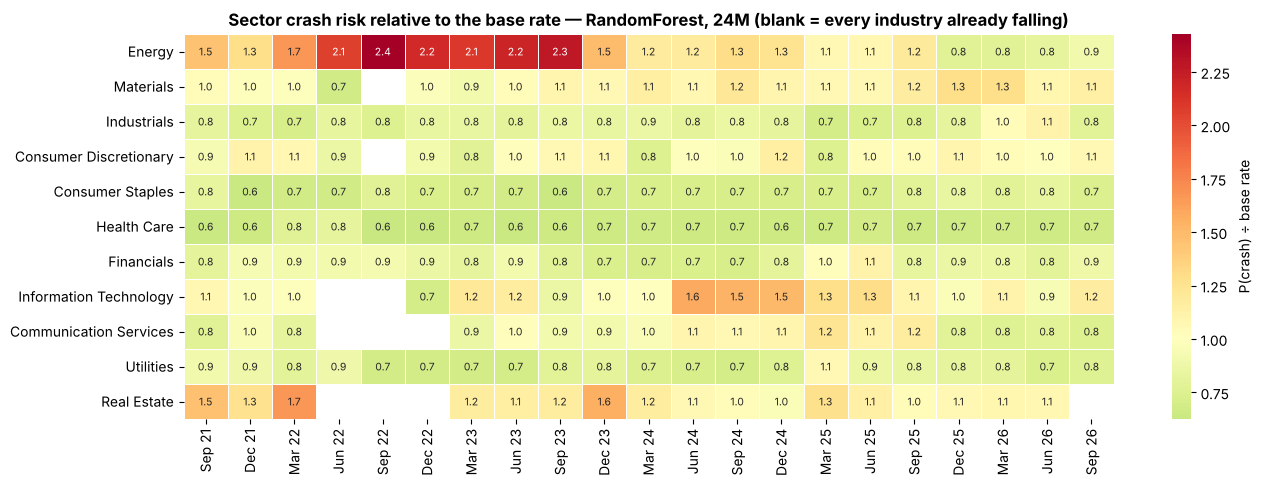

In [47]:
H5 = B[~B["Masked"]].loc[pd.IndexSlice[last - pd.DateOffset(years=5):, :], :].copy()
H5["Sector"] = H5.index.get_level_values("Industry").map(SECTOR_OF)
H5["wp"] = H5["MCap"] * H5[MAIN_MODEL] / H5["Base rate"]
grp = H5.groupby([pd.Grouper(level="Date"), "Sector"])
heat = (grp["wp"].sum() / grp["MCap"].sum()).unstack("Sector").T.reindex(list(GICS_MAP))
heat = heat.loc[:, heat.columns[::-1][::3][::-1]]                    # every third month, ending at the latest
fig, ax = plt.subplots(figsize=(15, 5))
sns.heatmap(heat, cmap="RdYlGn_r", center=1.0, annot=True, fmt=".1f", annot_kws={"size": 7.5}, linewidths=0.4,
            xticklabels=[f"{d:%b %y}" for d in heat.columns], cbar_kws={"label": "P(crash) ÷ base rate"}, ax=ax)
ax.set(xlabel="", ylabel="")
ax.set_title(f"Sector crash risk relative to the base rate — {MAIN_MODEL}, {MAIN_H}M (blank = every industry already falling)",
             fontsize=12, fontweight="bold")
save(fig, "decision_sector_heatmap")

# Part 11 — Robustness

## 11.1 Does the result survive other choices?
* **Purpose:** Check that the conclusions do not depend on one setting.
* **Method:** One setting is changed at a time and the 24-month walk-forward is rerun: relative crash threshold 20% or 40%, the absolute label, features with no cross-sectional ranks at all (winsorised), and the half-lives that were not chosen in 5.3. The comparison of interest is the pattern, not the third decimal: ranking skill (XS-AUC) against timing skill (Time-AUC) and probability skill (BSS).

In [48]:
for dd in (0.20, 0.40):
    lab = crash_label(rel_px, MAIN_H, dd).stack().rename(f"Crash_{MAIN_H}_dd{int(dd * 100)}")
    panel[lab.name] = lab.reindex(panel.index)
SPECS_2  = {m: MODEL_SPECS[m] for m in [BENCH_MODEL, MAIN_MODEL]}
RAW_SPEC = {BENCH_MODEL: ("logit", FEATS_RAW), MAIN_MODEL: ("rf", FEATS_RAW)}
main_lab = f"Crash_{MAIN_H}"
hl_name = lambda hl: "No time decay" if np.isinf(hl) else f"Half-life {hl:g} years"
SCENARIOS = {f"Baseline (relative {REL_DD:.0%}, {hl_name(HALF_LIFE).lower()})": PRED[MAIN_H],
             "Relative threshold 20%":          walk_forward(f"{main_lab}_dd20", SPECS_2, MAIN_H)[0],
             "Relative threshold 40%":          walk_forward(f"{main_lab}_dd40", SPECS_2, MAIN_H)[0],
             f"Absolute label ({ABS_DD:.0%})":  PRED_ABS,
             "Raw features (no ranks)":         walk_forward(main_lab, RAW_SPEC, MAIN_H, rows=panel.dropna(subset=FEATS_RAW))[0],
             **{hl_name(hl): walk_forward(main_lab, SPECS_2, MAIN_H, half_life=hl)[0] for hl in HALF_LIFE_GRID if hl != HALF_LIFE}}
rows = []
for name, pred in SCENARIOS.items():
    res = evaluate(early_warning(pred), list(SPECS_2))
    for m in SPECS_2:
        rows.append({"Scenario": name, "Model": m, **res.loc[m, ["N", "Crash rate", "XS-AUC", "Time-AUC", "AUC", "BSS", "BSS lo", "BSS hi"]].to_dict()})
robust = pd.DataFrame(rows).set_index(["Scenario", "Model"]).astype({"N": int})
robust.round(3)

N  Crash rate  XS-AUC  Time-AUC    AUC    BSS  BSS lo  BSS hi
Scenario                               Model                                                                          
Baseline (relative 30%, no time decay) Logit         28502       0.131   0.678     0.526  0.624  0.036   0.016   0.063
                                       RandomForest  28502       0.131   0.710     0.516  0.628  0.036   0.022   0.057
Relative threshold 20%                 Logit         28502       0.330   0.622     0.507  0.607  0.045   0.025   0.074
                                       RandomForest  28502       0.330   0.632     0.501  0.608  0.042   0.024   0.063
Relative threshold 40%                 Logit         28502       0.050   0.735     0.567  0.625  0.039   0.013   0.077
                                       RandomForest  28502       0.050   0.773     0.522  0.653  0.033   0.018   0.057
Absolute label (40%)                   Logit         28502       0.089   0.737     0.456  0.595  0.034   0.000   0.067
                                       RandomForest  28502       0.089   0.735     0.319  0.551  0.021   0.007   0.037
Raw features (no ranks)                Logit         28502       0.131   0.694     0.527  0.597  0.028  -0.003   0.059
                                       RandomForest  28502       0.131   0.684     0.540  0.615  0.030   0.007   0.053
Half-life 10 years                     Logit         28502       0.131   0.671     0.484  0.597  0.026   0.007   0.054
                                       RandomForest  28502       0.131   0.702     0.473  0.590  0.027   0.016   0.046
Half-life 20 years                     Logit         28502       0.131   0.677     0.507  0.611  0.032   0.013   0.060
                                       RandomForest  28502       0.131   0.707     0.496  0.611  0.033   0.019   0.054
Half-life 40 years                     Logit         28502       0.131   0.679     0.518  0.618  0.035   0.015   0.062
                                       RandomForest  28502       0.131   0.709     0.510  0.620  0.035   0.021   0.056

## 11.2 Overfitting: in-sample versus out-of-sample
* **Purpose:** Measure how much of the fit does not carry over to new data.
* **Method:** Both scores are AUCs inside a single calendar year, so they measure the same thing. In-sample: the average over the years of the training set. Out-of-sample: the following test year. Both are averaged over the fits whose test year contains crashes and non-crashes. A large gap means the model memorises the training period.

In [49]:
rows = []
for H in H_LIST:
    ew_y = EW[H].assign(Year=EW[H].index.get_level_values("Date").year)
    for m in MODELS:
        oos = pd.Series({yr: roc_auc_score(g["y"], g[m]) for yr, g in ew_y.groupby("Year") if g["y"].nunique() == 2})
        ins = INSAMPLE[H].query("Model == @m").set_index("Year")["AUC in-sample"].reindex(oos.index)
        rows.append({"Horizon (months)": H, "Model": m, "Fits": len(oos), "AUC in-sample": ins.mean(),
                     "AUC next year": oos.mean(), "Gap": ins.mean() - oos.mean()})
overfit = pd.DataFrame(rows).set_index(["Horizon (months)", "Model"])
overfit.round(3)

Fits  AUC in-sample  AUC next year    Gap
Horizon (months) Model                                                  
6                Logit-Vol       33          0.882          0.867  0.015
                 Logit           33          0.892          0.837  0.055
                 RandomForest    33          0.955          0.862  0.093
12               Logit-Vol       57          0.736          0.798 -0.062
                 Logit           57          0.773          0.761  0.011
                 RandomForest    57          0.850          0.781  0.069
24               Logit-Vol       65          0.666          0.700 -0.033
                 Logit           65          0.671          0.670  0.001
                 RandomForest    65          0.728          0.706  0.022

# Part 12 — Summary

## 12.1 Headline numbers
* **Purpose:** Collect the results that the conclusion rests on in one table.
* **Method:** All values are taken from the tables above for the 24-month horizon; nothing is recomputed.

In [50]:
r_main, r_vol = results[MAIN_H].loc[MAIN_MODEL], results[MAIN_H].loc[VOL_MODEL]
ew_dates = EW[MAIN_H].index.get_level_values("Date")
strict = gsy_table.loc["Strict run-up (RunUp = 1)"]
vt = lambda i, m: "{:+.3f} [{:+.3f}, {:+.3f}]".format(*vol_test.loc[(vol_test.index[i][0], m), ["ΔXS-AUC vs Logit-Vol", "Δ lo", "Δ hi"]])
hv = within_vol.loc["High volatility third"]
ci = lambda r, k: f"{r[k]:.3f} [{r[k + ' lo']:.3f}, {r[k + ' hi']:.3f}]"
bt = BT_TABLE.loc["Cap-weighted"]
tb = bt.loc[f"{MAIN_MODEL}: top-{ALERT_K} to T-bills"]
summary = pd.Series({
    "Sample (forecast months with a known outcome)":         f"{ew_dates.min():%Y-%m} to {ew_dates.max():%Y-%m}, {int(r_main['N']):,} early-warning industry-months",
    "Label / half-life chosen in 5.3":                       f"relative crash >= {REL_DD:.0%} vs market / {hl_name(HALF_LIFE).lower()}",
    f"Which industry? XS-AUC ({MAIN_MODEL})":                ci(r_main, "XS-AUC"),
    f"Which industry? XS-AUC ({VOL_MODEL} baseline)":        ci(r_vol, "XS-AUC"),
    f"ΔXS-AUC, {MAIN_MODEL} − {VOL_MODEL} (headline label)": vt(0, MAIN_MODEL),
    f"ΔXS-AUC, {MAIN_MODEL} − {VOL_MODEL} (absolute label)": vt(-1, MAIN_MODEL),
    f"XS-AUC inside the high-volatility third ({MAIN_MODEL} / {VOL_MODEL})": f"{hv.loc[MAIN_MODEL, 'XS-AUC']:.3f} / {hv.loc[VOL_MODEL, 'XS-AUC']:.3f}",
    f"Strict run-ups (N = {int(strict.loc[MAIN_MODEL, 'N'])}, crash rate {strict.loc[MAIN_MODEL, 'Crash rate']:.0%}): AUC {MAIN_MODEL}": ci(strict.loc[MAIN_MODEL], "AUC"),
    f"Strict run-ups: AUC {BENCH_MODEL} / {VOL_MODEL}":      f"{strict.loc[BENCH_MODEL, 'AUC']:.3f} / {strict.loc[VOL_MODEL, 'AUC']:.3f}",
    f"When? Time-AUC ({MAIN_MODEL})":                        ci(r_main, "Time-AUC"),
    "When? Time-AUC (base rate only)":                       ci(results[MAIN_H].loc["Base rate"], "Time-AUC"),
    f"Pooled AUC ({MAIN_MODEL})":                            ci(r_main, "AUC"),
    f"Probability skill, BSS ({MAIN_MODEL})":                ci(r_main, "BSS"),
    f"From {STAGE1_TEST_YEAR}, Time-AUC: {MAIN_MODEL} / two-stage": f"{two_stage.loc[MAIN_MODEL, 'Time-AUC']:.3f} / {two_stage.loc['Two-stage', 'Time-AUC']:.3f}",
    f"From {STAGE1_TEST_YEAR}, BSS: {MAIN_MODEL} / two-stage": f"{two_stage.loc[MAIN_MODEL, 'BSS']:+.3f} / {two_stage.loc['Two-stage', 'BSS']:+.3f}",
    "Stage 1 out-of-sample R² vs base rate":                 f"{stage1_skill.loc['Out-of-sample R² vs base rate', 'Stage 1']:+.3f}",
    f"Top-{ALERT_K} alert: crash rate / control matched on return": "{:.1%} / {:.1%}".format(*control_table.loc[("24M return", MAIN_MODEL), ["Crash rate | alert", "Matched control"]]),
    f"Top-{ALERT_K} alert: crash rate / control matched on return and volatility": "{:.1%} / {:.1%} (diff {:+.1%} [{:+.1%}, {:+.1%}])".format(
        *control_table.loc[("24M return and volatility", MAIN_MODEL), ["Crash rate | alert", "Matched control", "Difference", "Diff lo", "Diff hi"]]),
    f"Long–short FF3 alpha per year ({MAIN_MODEL})":         f"{ls_table.loc[MAIN_MODEL, 'FF3 alpha (ann.)']:+.1%} (t = {ls_table.loc[MAIN_MODEL, 't FF3']:.2f})",
    f"Long–short FF3 alpha per year ({VOL_MODEL})":          f"{ls_table.loc[VOL_MODEL, 'FF3 alpha (ann.)']:+.1%} (t = {ls_table.loc[VOL_MODEL, 't FF3']:.2f})",
    "Overlay to T-bills: Δ return vs control per year":      f"{tb['Δ ann. return vs control']:+.2%} [{tb['Δ lo']:+.2%}, {tb['Δ hi']:+.2%}]",
    "Overlay max drawdown: overlay / control / matched":     f"{tb['Max drawdown']:.1%} / {bt.loc['Control', 'Max drawdown']:.1%} / {bt.loc['Exposure-matched control', 'Max drawdown']:.1%}",
    "Overlay Sharpe: overlay / control / matched":           f"{tb['Sharpe']:.2f} / {bt.loc['Control', 'Sharpe']:.2f} / {bt.loc['Exposure-matched control', 'Sharpe']:.2f}",
    "Breadth → 24M market return, 5 measures (8.5)":         f"{int((market_reg['Coefficient'] < 0).sum())} negative, {int((market_reg['Coefficient'] > 0).sum())} positive; "
                                                             f"coefficients {market_reg['Coefficient'].min():+.3f} to {market_reg['Coefficient'].max():+.3f}",
}, name=f"{MAIN_H}-month horizon")
summary.to_frame()

,24-month horizon
Sample (forecast months with a known outcome),"1960-01 to 2024-09, 28,502 early-warning industry-months"
Label / half-life chosen in 5.3,relative crash >= 30% vs market / no time decay
Which industry? XS-AUC (RandomForest),"0.710 [0.682, 0.742]"
Which industry? XS-AUC (Logit-Vol baseline),"0.703 [0.666, 0.742]"
"ΔXS-AUC, RandomForest − Logit-Vol (headline label)","+0.007 [-0.017, +0.040]"
"ΔXS-AUC, RandomForest − Logit-Vol (absolute label)","-0.024 [-0.045, +0.001]"
XS-AUC inside the high-volatility third (RandomForest / Logit-Vol),0.670 / 0.677
"Strict run-ups (N = 272, crash rate 58%): AUC RandomForest","0.559 [0.251, 0.797]"
Strict run-ups: AUC Logit / Logit-Vol,0.311 / 0.535
When? Time-AUC (RandomForest),"0.516 [0.434, 0.575]"


## 12.2 What the investor can and cannot use
* **Purpose:** State the conclusion in terms of decisions.
* **Method:** Each answer points to the test that supports it. Numbers are for the 24-month horizon and the headline label (a fall of at least 30% relative to the market), out-of-sample, forecast months 1960-01 to 2024-09.

| Question | Answer | Evidence |
|---|---|---|
| Which industries are riskier than the others this month? | **Yes** | XS-AUC 0.71 [0.68, 0.74] (6.2). The five alerted industries crash 27% of the time against 17% for industries with a similar past return **and** volatility (6.6). |
| Is that a bubble signal? | **Not shown** | A Logit with two volatility ranks reaches XS-AUC 0.70; the difference to the Random Forest is +0.007 with an interval that contains 0 (6.4). Volatility is about 60% of SHAP importance in all four crises (7.1). Bubble signals, the HMM regime and own-history features add nothing significant after the FDR adjustment (6.7). Some ranking skill remains inside each volatility group (XS-AUC 0.60–0.67), but the volatility-only model shows it as well. |
| Can it tell which run-ups will crash? | **No** | In strict run-ups (N = 272, crash rate 58%) the Random Forest AUC is 0.56 with an interval from 0.25 to 0.80, and the Logit ranks in the wrong order (AUC 0.31, interval below 0.5) (6.5). Forecasts for industries inside a run-up are flagged in 10.1 and should not be relied on. |
| When will the crashes come? | **No** | Time-AUC 0.52, interval contains 0.5 (6.2). The market-level Stage 1 model has a negative out-of-sample R² and the two-stage model is not better (8.4). Breadth measures disagree in sign as predictors of the market return (8.5). |
| Are the probabilities the right size? | **Modestly better than the base rate** | BSS 0.036 [0.022, 0.057] (6.2). |
| Does avoiding the riskiest industries raise returns? | **No** | The low-risk minus high-risk portfolio has a negative alpha (−3.7% a year, t = −2.3): the industries rated risky earned more, not less (9.2). Removing the top five costs about 1.3% a year, and the lower drawdown is matched by holding the same share of T-bills (9.3). |

**Recommended use.** The system is a monthly risk-ranking and monitoring tool. It tells an investor where the risk of a large industry-specific fall is concentrated (10.1, 10.2), which supports position limits, closer due diligence and stress tests for the flagged industries. It should not be presented as a bubble detector, a timing signal or a source of extra return. The pattern agrees with Greenwood, Shleifer & You (2019) on one point: a strict run-up is followed by a crash far more often than usual (58% against 13% for all months), but the models here cannot tell which run-ups those are.

## 12.3 Limitations
* **Choices made after a first full run:** the first version used the absolute 40% label as headline and a fixed 20-year half-life. After reviewing it, the headline was changed to the relative label and the half-life is now chosen on 1945–1959 (5.3). Results for the earlier choices are kept in 6.4 and 11.1. Because of this history, the headline numbers are not a clean pre-registered test.
* **Universe:** 48 Fama–French industry portfolios (49 minus "Other"), not tradable funds; the 11 sectors only approximate GICS. Data are revised, not real-time vintages.
* **Concentration:** one industry can hold more than a fifth of total market cap (10.1). Cap-weighted breadth and the cap-weighted overlay are then dominated by that industry.
* **Target:** a 30% fall relative to the market is an industry-specific crash, not proof that a bubble burst. The "already falling" mask still uses the industry's own price.
* **Dependence:** industries crash together and 24-month labels overlap, so the effective sample is far smaller than the row count. Intervals use a month-block bootstrap and depend on the block length. The strict run-up sample has only 272 rows.
* **Layer 1:** the GSADF test uses lag 0. Its flags are more frequent in steadily rising defensive sectors than in Information Technology, and the dot-com episode is flagged in only a small share of months (2.2); flags that appear in many sectors at once follow market-wide recoveries. It detects sustained trends rather than industry-specific bubbles.
* **Layer 2:** the HMM states are volatility regimes. "High volatility" covers 44% of all days, so it does not single out crises (3.4).
* **Market level:** neither the Stage 1 model (8.4) nor the breadth regressions (8.5, in-sample) support a market-timing claim. Section 8.2 is a hindsight case study.
* **Backtest:** flat 10 bps cost, no taxes or market impact, monthly rebalancing. The long–short portfolio measures the ranking; shorting is not a recommended action.
* **Not done:** LPPLS confidence indicators (Demirer et al., 2017) and a three-way crash / plateau / continue label (Zhao & Sornette) are left for future work.

**References**
* Greenwood, R., Shleifer, A., & You, Y. (2019). Bubbles for Fama. *Journal of Financial Economics*, 131(1), 20–43.
* Phillips, P. C. B., Shi, S., & Yu, J. (2015). Testing for multiple bubbles. *International Economic Review*, 56(4), 1043–1078.
* Demirer, R., Demos, G., Gupta, R., & Sornette, D. (2017). On the predictability of stock market bubbles: evidence from LPPLS confidence multi-scale indicators.
* Zhao, D., & Sornette, D. Bubbles for Fama from Sornette. Swiss Finance Institute Research Paper 21-94.